<a href="https://colab.research.google.com/github/haniyathul/TESIS-HANIY/blob/main/PEMBANGKITAN_DATA_SIMULASI_1_(WEAK).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WEAK SPATIAL DEPENDENCE

In [ ]:

# ================================================================
# FILE WEAK — rho = 0.20
# PEMBANGKITAN DATA SIMULASI SPASIAL
# ================================================================

import warnings
warnings.filterwarnings("ignore")

import gc
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy.sparse as sp

from scipy.spatial import cKDTree
from scipy.sparse.linalg import spsolve
from scipy.interpolate import UnivariateSpline

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan


# ================================================================
# DISPLAY
# ================================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 3000)
pd.set_option("display.max_colwidth", None)


# ================================================================
# 1. KONFIGURASI WEAK
# ================================================================

RHO_WEAK = 0.20
ERROR_SD = 0.25
SPLINE_SMOOTH = 0.60

PATTERNS = ["Hotspot", "Koridor", "Gelombang"]
W_METHODS = ["KNN5", "DISTANCE", "IDW"]
ERROR_TYPES = ["Homogeneous", "Heterogeneous"]
MODEL_PREDICTORS = ["X1", "X2", "X3"]

BASE_OUTPUT_WEAK = Path("/content/SIMULASI_WEAK_RHO020")
BASE_OUTPUT_WEAK.mkdir(parents=True, exist_ok=True)


# ================================================================
# 2. BETA — DIBANGKITKAN SATU KALI, LALU DIKUNCI
#    Gunakan seed yang sama nanti untuk MODERATE dan STRONG
# ================================================================

BETA_SEED = 2025
rng_beta = np.random.default_rng(BETA_SEED)

BETA_1, BETA_2, BETA_3 = rng_beta.uniform(
    -2,
    2,
    size=3
)

print("=" * 70)
print("KOEFISIEN NONLINEAR — DIPAKAI SAMA UNTUK SEMUA SKENARIO")
print("=" * 70)
print(f"beta1 = {BETA_1:.6f}")
print(f"beta2 = {BETA_2:.6f}")
print(f"beta3 = {BETA_3:.6f}")


# ================================================================
# 3. FUNGSI BANTU
# ================================================================

def standardize(v):
    v = np.asarray(v, dtype=float)
    sd = np.std(v, ddof=0)

    if sd <= 1e-12:
        return v - np.mean(v)

    return (v - np.mean(v)) / sd


def row_standardize(W):
    W = W.tocsr().astype(float)

    row_sum = np.asarray(
        W.sum(axis=1)
    ).ravel()

    inv = np.zeros_like(
        row_sum,
        dtype=float
    )

    valid = row_sum > 0
    inv[valid] = 1.0 / row_sum[valid]

    return (
        sp.diags(inv)
        @ W
    ).tocsr()


def gaussian_hotspot(
    u,
    v,
    cu,
    cv,
    sigma,
    amplitude=1.0
):
    return (
        amplitude
        *
        np.exp(
            -(
                (u-cu)**2
                +
                (v-cv)**2
            )
            /
            (2*sigma**2)
        )
    )


def smooth_spline_curve(
    x,
    y,
    smooth_fraction=0.60
):
    temp = pd.DataFrame({
        "x": np.asarray(x),
        "y": np.asarray(y)
    })

    temp["x_round"] = temp["x"].round(8)

    temp = (
        temp
        .groupby("x_round", as_index=False)
        .agg(
            x=("x", "mean"),
            y=("y", "mean")
        )
        .sort_values("x")
    )

    xs = temp["x"].to_numpy()
    ys = temp["y"].to_numpy()

    if len(xs) < 4:
        return xs, ys

    smoothing = (
        smooth_fraction
        *
        len(xs)
        *
        max(np.var(ys), 1e-6)
    )

    spline = UnivariateSpline(
        xs,
        ys,
        k=3,
        s=smoothing
    )

    xx = np.linspace(
        xs.min(),
        xs.max(),
        400
    )

    yy = spline(xx)

    return xx, yy


def moran_I(y, W):
    y = np.asarray(
        y,
        dtype=float
    )

    z = y - np.mean(y)

    denominator = float(
        z @ z
    )

    if denominator <= 0:
        return np.nan

    numerator = float(
        z @ (W @ z)
    )

    S0 = float(
        W.sum()
    )

    return float(
        (len(y)/S0)
        *
        (numerator/denominator)
    )


# ================================================================
# 4. FUNGSI UTAMA
# SATU GRID = SEMUA PROSES + VISUAL + VALIDASI
# ================================================================

def run_weak_grid(grid_size):

    rho = RHO_WEAK
    N = grid_size * grid_size

    OUTPUT_DIR = (
        BASE_OUTPUT_WEAK
        /
        f"GRID{grid_size}"
    )

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    print("\n")
    print("=" * 120)
    print(f"WEAK SPATIAL DEPENDENCE — rho={rho:.2f}")
    print(f"GRID {grid_size} × {grid_size}")
    print(f"N = {N}")
    print("=" * 120)


    # ============================================================
    # A. LOKASI / GRID
    # Koordinat asli = u_raw, v_raw
    # Koordinat normalisasi = u, v
    # ============================================================

    grid_row = np.repeat(
        np.arange(grid_size),
        grid_size
    )

    grid_col = np.tile(
        np.arange(grid_size),
        grid_size
    )

    u_raw = grid_col.astype(float)
    v_raw = grid_row.astype(float)

    coords_raw = np.column_stack([
        u_raw,
        v_raw
    ])

    u = (
        u_raw
        /
        (grid_size - 1)
    )

    v = (
        v_raw
        /
        (grid_size - 1)
    )

    GRID = pd.DataFrame({
        "Location_ID": np.arange(1, N+1),
        "Grid_Row": grid_row,
        "Grid_Col": grid_col,
        "u_raw": u_raw,
        "v_raw": v_raw,
        "u": u,
        "v": v
    })

    print("\n✅ A. GRID / KOORDINAT BERHASIL")


    # ============================================================
    # VISUAL 0 — TITIK LOKASI AWAL
    # ============================================================

    fig, ax = plt.subplots(
        figsize=(8, 8)
    )

    ax.scatter(
        u_raw,
        v_raw,
        s=30
    )

    # Label ID hanya untuk grid kecil supaya tidak terlalu penuh
    if grid_size <= 20:
        for i in range(N):
            ax.text(
                u_raw[i],
                v_raw[i] + 0.08,
                str(i+1),
                fontsize=6,
                ha="center"
            )

    ax.set_title(
        (
            "Titik Lokasi Awal Sebelum Pembentukan Y\n"
            f"Grid {grid_size}×{grid_size}"
        ),
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel("Koordinat u (asli)")
    ax.set_ylabel("Koordinat v (asli)")
    ax.set_aspect("equal")
    ax.grid(alpha=.20)

    FILE_VIS0 = (
        OUTPUT_DIR
        /
        "00_TITIK_LOKASI_AWAL.png"
    )

    plt.tight_layout()
    plt.savefig(
        FILE_VIS0,
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


    # ============================================================
    # B. POLA SPASIAL LATEN Z(s)
    # ============================================================

    # ---------------- HOTSPOT ----------------

    hotspot_big = gaussian_hotspot(
        u,
        v,
        cu=0.32,
        cv=0.56,
        sigma=0.17,
        amplitude=1.80
    )

    hotspot_small = gaussian_hotspot(
        u,
        v,
        cu=0.74,
        cv=0.76,
        sigma=0.085,
        amplitude=1.30
    )

    hotspot_irregular = (
        0.08
        *
        np.sin(
            3*np.pi*u
        )
        *
        np.cos(
            2*np.pi*v
        )
    )

    HOTSPOT_PARTS = {
        "besar": standardize(hotspot_big),
        "kecil": standardize(hotspot_small),
        "gabungan": standardize(
            hotspot_big
            +
            hotspot_small
            +
            hotspot_irregular
        )
    }


    # ---------------- KORIDOR ----------------

    centerline = (
        0.20
        +
        0.54*u
        +
        0.10*np.sin(
            2.6*np.pi*u + 0.40
        )
        -
        0.045*np.sin(
            5.4*np.pi*u
        )
    )

    corridor_distance = np.abs(
        v - centerline
    )

    corridor_width = (
        0.065
        +
        0.020
        *
        (
            1
            +
            np.sin(
                3*np.pi*u
            )
        )
    )

    corridor_main = np.exp(
        -(corridor_distance**2)
        /
        (
            2
            *
            corridor_width**2
        )
    )

    taper_left = (
        1
        /
        (
            1
            +
            np.exp(
                -(u-0.10)/0.025
            )
        )
    )

    taper_right = (
        1
        /
        (
            1
            +
            np.exp(
                (u-0.90)/0.025
            )
        )
    )

    corridor_main = (
        corridor_main
        *
        taper_left
        *
        taper_right
    )

    corridor_bump1 = gaussian_hotspot(
        u,
        v,
        cu=0.28,
        cv=0.38,
        sigma=0.085,
        amplitude=0.45
    )

    corridor_bump2 = gaussian_hotspot(
        u,
        v,
        cu=0.72,
        cv=0.67,
        sigma=0.070,
        amplitude=0.35
    )

    corridor_local = (
        corridor_bump1
        +
        corridor_bump2
    )

    corridor_roughness = (
        0.08
        *
        np.sin(
            5*np.pi*u
            +
            1.2*v
        )
    )

    CORRIDOR_PARTS = {
        "utama": standardize(corridor_main),
        "lokal": standardize(corridor_local),
        "gabungan": standardize(
            1.15*corridor_main
            +
            corridor_local
            +
            corridor_roughness
        )
    }


    # ---------------- GELOMBANG ----------------

    wave_large = (
        1.15
        *
        np.sin(
            2.5*np.pi*u
            +
            0.30
        )
        +
        0.95
        *
        np.cos(
            2.1*np.pi*v
            -
            0.20
        )
    )

    wave_secondary = (
        0.55
        *
        np.sin(
            4.0*np.pi*u
            -
            1.7*np.pi*v
        )
    )

    wave_diagonal = (
        0.40
        *
        np.sin(
            2*np.pi*(u+v)
            +
            0.50
        )
    )

    WAVE_PARTS = {
        "besar": standardize(wave_large),
        "kecil": standardize(
            wave_secondary
            +
            wave_diagonal
        ),
        "gabungan": standardize(
            wave_large
            +
            wave_secondary
            +
            wave_diagonal
        )
    }

    Z_PATTERN = {
        "Hotspot": HOTSPOT_PARTS["gabungan"],
        "Koridor": CORRIDOR_PARTS["gabungan"],
        "Gelombang": WAVE_PARTS["gabungan"]
    }

    print("✅ B. Z(s) SELESAI")


    # ============================================================
    # VISUAL 1 — POLA Z(s)
    # ============================================================

    fig, axes = plt.subplots(
        3,
        3,
        figsize=(12, 12)
    )

    visual_components = [
        (
            "Hotspot",
            HOTSPOT_PARTS["besar"],
            HOTSPOT_PARTS["kecil"],
            HOTSPOT_PARTS["gabungan"]
        ),
        (
            "Koridor",
            CORRIDOR_PARTS["utama"],
            CORRIDOR_PARTS["lokal"],
            CORRIDOR_PARTS["gabungan"]
        ),
        (
            "Gelombang",
            WAVE_PARTS["besar"],
            WAVE_PARTS["kecil"],
            WAVE_PARTS["gabungan"]
        )
    ]

    titles = [
        "Struktur Besar/Utama",
        "Struktur Kecil/Lokal",
        "Gabungan Z(s)"
    ]

    for r, (
        pattern,
        part1,
        part2,
        combined
    ) in enumerate(
        visual_components
    ):

        for c, values in enumerate(
            [
                part1,
                part2,
                combined
            ]
        ):

            matrix = values.reshape(
                grid_size,
                grid_size
            )

            im = axes[r, c].imshow(
                matrix,
                origin="lower",
                cmap="viridis",
                interpolation="nearest"
            )

            if r == 0:
                axes[r, c].set_title(
                    titles[c],
                    fontweight="bold"
                )

            if c == 0:
                axes[r, c].set_ylabel(
                    pattern,
                    fontweight="bold"
                )

            axes[r, c].set_xticks([])
            axes[r, c].set_yticks([])

            plt.colorbar(
                im,
                ax=axes[r, c],
                fraction=.046,
                pad=.04
            )

    fig.suptitle(
        (
            f"Latent Spatial Pattern Z(s)\n"
            f"Grid {grid_size}×{grid_size} | Weak rho=0.20"
        ),
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    FILE_VIS1 = (
        OUTPUT_DIR
        /
        "01_LATENT_PATTERN.png"
    )

    plt.savefig(
        FILE_VIS1,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


    # ============================================================
    # C. X1, X2, X3 + g(X)
    # ============================================================

    rng_x = np.random.default_rng(
        2026 + grid_size
    )

    X_DATA = rng_x.normal(
        0,
        1,
        size=(N, 3)
    )

    for j in range(3):
        X_DATA[:, j] = standardize(
            X_DATA[:, j]
        )

    X1 = X_DATA[:, 0]
    X2 = X_DATA[:, 1]
    X3 = X_DATA[:, 2]


    # ------------------------------------------------------------
    # NONLINEAR COMPONENT BARU
    #
    # g(X) = beta1 X1^2
    #      + beta2 X1 X2
    #      + beta3 sin(X3)
    # ------------------------------------------------------------

    GX_RAW = (
        BETA_1
        *
        (X1**2)

        +

        BETA_2
        *
        (X1*X2)

        +

        BETA_3
        *
        np.sin(X3)
    )


    # ------------------------------------------------------------
    # PENTING:
    # Standardisasi g(X) agar skalanya sebanding dengan Z(s)
    # ------------------------------------------------------------

    GX = standardize(
        GX_RAW
    )

    print("✅ C. X1, X2, X3 + g(X) SELESAI")

    print(
        (
            f"   beta = "
            f"({BETA_1:.4f}, "
            f"{BETA_2:.4f}, "
            f"{BETA_3:.4f})"
        )
    )

    print(
        f"   SD g(X) setelah standardisasi = {np.std(GX):.4f}"
    )


    # ============================================================
    # VISUAL 2 — TRUE NONLINEARITY
    # ============================================================

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 4.5)
    )

    X_DICT = {
        "X1": X1,
        "X2": X2,
        "X3": X3
    }

    for ax, xname in zip(
        axes,
        MODEL_PREDICTORS
    ):

        xx_line, yy_line = smooth_spline_curve(
            X_DICT[xname],
            GX,
            smooth_fraction=0.25
        )

        ax.scatter(
            X_DICT[xname],
            GX,
            alpha=.30,
            s=18
        )

        ax.plot(
            xx_line,
            yy_line,
            linewidth=3
        )

        ax.set_title(
            f"{xname} vs g(X)",
            fontweight="bold"
        )

        ax.set_xlabel(xname)
        ax.set_ylabel("g(X) terstandar")
        ax.grid(alpha=.20)

    fig.suptitle(
        (
            "Cek Nonlinearitas Sebenarnya pada DGP\n"
            f"Grid {grid_size}×{grid_size}"
        ),
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    FILE_VIS2 = (
        OUTPUT_DIR
        /
        "02_TRUE_NONLINEAR_SPLINE.png"
    )

    plt.savefig(
        FILE_VIS2,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


    # ============================================================
    # D. BUILD W
    # ============================================================

    tree = cKDTree(
        coords_raw
    )


    # ---------------- KNN5 ----------------

    _, indices_knn = tree.query(
        coords_raw,
        k=6
    )

    rows_knn = np.repeat(
        np.arange(N),
        5
    )

    cols_knn = (
        indices_knn[:, 1:6]
        .reshape(-1)
    )

    vals_knn = np.ones(
        len(rows_knn)
    )

    W_KNN5 = sp.csr_matrix(
        (
            vals_knn,
            (
                rows_knn,
                cols_knn
            )
        ),
        shape=(N, N)
    )

    W_KNN5 = row_standardize(
        W_KNN5
    )


    # ---------------- DISTANCE BAND <= 1.5 ----------------

    pairs_distance = np.array(
        list(
            tree.query_pairs(
                r=1.5
            )
        ),
        dtype=int
    )

    if len(pairs_distance) > 0:

        rows_d = np.concatenate([
            pairs_distance[:, 0],
            pairs_distance[:, 1]
        ])

        cols_d = np.concatenate([
            pairs_distance[:, 1],
            pairs_distance[:, 0]
        ])

        vals_d = np.ones(
            len(rows_d)
        )

    else:

        rows_d = np.array(
            [],
            dtype=int
        )

        cols_d = np.array(
            [],
            dtype=int
        )

        vals_d = np.array(
            [],
            dtype=float
        )

    W_DISTANCE = sp.csr_matrix(
        (
            vals_d,
            (
                rows_d,
                cols_d
            )
        ),
        shape=(N, N)
    )

    W_DISTANCE = row_standardize(
        W_DISTANCE
    )


    # ---------------- IDW radius 2.5 ----------------

    pairs_idw = np.array(
        list(
            tree.query_pairs(
                r=2.5
            )
        ),
        dtype=int
    )

    if len(pairs_idw) > 0:

        i1 = pairs_idw[:, 0]
        i2 = pairs_idw[:, 1]

        dist_idw = np.linalg.norm(
            coords_raw[i1]
            -
            coords_raw[i2],
            axis=1
        )

        weight_idw = (
            1.0
            /
            dist_idw
        )

        rows_i = np.concatenate([
            i1,
            i2
        ])

        cols_i = np.concatenate([
            i2,
            i1
        ])

        vals_i = np.concatenate([
            weight_idw,
            weight_idw
        ])

    else:

        rows_i = np.array(
            [],
            dtype=int
        )

        cols_i = np.array(
            [],
            dtype=int
        )

        vals_i = np.array(
            [],
            dtype=float
        )

    W_IDW = sp.csr_matrix(
        (
            vals_i,
            (
                rows_i,
                cols_i
            )
        ),
        shape=(N, N)
    )

    W_IDW = row_standardize(
        W_IDW
    )


    W_STORE = {
        "KNN5": W_KNN5,
        "DISTANCE": W_DISTANCE,
        "IDW": W_IDW
    }


    # ============================================================
    # INFORMASI W
    # ============================================================

    W_INFO_ROWS = []

    for method in W_METHODS:

        W = W_STORE[
            method
        ]

        counts = np.diff(
            W.indptr
        )

        W_INFO_ROWS.append({

            "Grid":
                f"{grid_size}x{grid_size}",

            "W_Method":
                method,

            "Min_Neighbor":
                int(
                    counts.min()
                ),

            "Mean_Neighbor":
                float(
                    counts.mean()
                ),

            "Max_Neighbor":
                int(
                    counts.max()
                )

        })

    W_INFO = pd.DataFrame(
        W_INFO_ROWS
    )

    print("✅ D. W SELESAI")
    display(
        W_INFO.round(2)
    )


    # ============================================================
    # VISUAL 3 — W
    # ============================================================

    target_index = np.argmin(
        (u-.5)**2
        +
        (v-.5)**2
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    for ax, method in zip(
        axes,
        W_METHODS
    ):

        W = W_STORE[
            method
        ].tocsr()

        start = W.indptr[
            target_index
        ]

        end = W.indptr[
            target_index+1
        ]

        neighbors = W.indices[
            start:end
        ]

        ax.scatter(
            u_raw,
            v_raw,
            s=12,
            alpha=.20
        )

        ax.scatter(
            u_raw[neighbors],
            v_raw[neighbors],
            s=70,
            label="Tetangga"
        )

        ax.scatter(
            u_raw[target_index],
            v_raw[target_index],
            marker="*",
            s=220,
            label="Lokasi pusat"
        )

        for j in neighbors:

            ax.plot(
                [
                    u_raw[target_index],
                    u_raw[j]
                ],
                [
                    v_raw[target_index],
                    v_raw[j]
                ],
                linewidth=.8,
                alpha=.50
            )

        title_w = {
            "KNN5": "KNN-5",
            "DISTANCE": "Distance Band",
            "IDW": "IDW"
        }[
            method
        ]

        ax.set_title(
            (
                f"{title_w}\n"
                f"k={len(neighbors)}"
            ),
            fontweight="bold"
        )

        ax.set_aspect("equal")
        ax.legend(
            fontsize=7
        )

    fig.suptitle(
        (
            "Struktur Ketetanggaan W\n"
            f"Grid {grid_size}×{grid_size}"
        ),
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    FILE_VIS3 = (
        OUTPUT_DIR
        /
        "03_STRUKTUR_W.png"
    )

    plt.savefig(
        FILE_VIS3,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


    # ============================================================
    # E. ERROR
    # ============================================================

    rng_error = np.random.default_rng(
        2027 + grid_size
    )

    BASE_ERROR = rng_error.normal(
        0,
        1,
        N
    )

    def generate_error(
        error_type
    ):

        if (
            error_type
            ==
            "Homogeneous"
        ):

            variance = np.ones(
                N
            )

            error = (
                ERROR_SD
                *
                BASE_ERROR
            )

        else:

            # Dua zona berdasarkan koordinat u
            variance = np.where(
                u <= .5,
                .5,
                1.5
            )

            error = (
                ERROR_SD
                *
                np.sqrt(
                    variance
                )
                *
                BASE_ERROR
            )

        return (
            error,
            variance
        )


    # ============================================================
    # F. GENERATE 18 SKENARIO
    #
    # DGP FINAL:
    # eta = Z(s) + g(X) + error
    # Y   = (I - rho W)^(-1) eta
    # ============================================================

    ALL_DATA = []

    for pattern in PATTERNS:

        Z_SPATIAL = Z_PATTERN[
            pattern
        ]

        for error_type in ERROR_TYPES:

            ERROR, ERROR_VARIANCE = (
                generate_error(
                    error_type
                )
            )

            ETA = (
                Z_SPATIAL
                +
                GX
                +
                ERROR
            )

            for w_method in W_METHODS:

                W = W_STORE[
                    w_method
                ]

                A = (
                    sp.eye(
                        N,
                        format="csr"
                    )
                    -
                    rho
                    *
                    W
                )

                Y = spsolve(
                    A,
                    ETA
                )

                Y = np.asarray(
                    Y,
                    dtype=float
                )

                MORAN_Y = moran_I(
                    Y,
                    W
                )

                CORR_ZY = float(
                    np.corrcoef(
                        Z_SPATIAL,
                        Y
                    )[0, 1]
                )

                scenario_id = (
                    f"G{grid_size}_"
                    f"{pattern.upper()}_"
                    f"{w_method}_"
                    f"{'HOMO' if error_type == 'Homogeneous' else 'HETERO'}_"
                    f"RHO20"
                )

                temp = GRID.copy()

                temp[
                    "Scenario_ID"
                ] = scenario_id

                temp[
                    "Grid"
                ] = (
                    f"{grid_size}x{grid_size}"
                )

                temp["N"] = N
                temp["Strength"] = "Weak"
                temp["Rho"] = rho
                temp["Pattern"] = pattern
                temp["W_Method"] = w_method
                temp["Error_Structure"] = error_type

                temp[
                    "Z_spatial_latent"
                ] = Z_SPATIAL

                temp["X1"] = X1
                temp["X2"] = X2
                temp["X3"] = X3

                temp[
                    "Beta1"
                ] = BETA_1

                temp[
                    "Beta2"
                ] = BETA_2

                temp[
                    "Beta3"
                ] = BETA_3

                temp[
                    "gX_raw"
                ] = GX_RAW

                temp[
                    "gX_nonlinear"
                ] = GX

                # Tetap disimpan untuk kompatibilitas tabel lama
                temp[
                    "Spatial_Signal"
                ] = Z_SPATIAL

                temp[
                    "Error"
                ] = ERROR

                temp[
                    "Error_Variance"
                ] = ERROR_VARIANCE

                temp[
                    "Eta"
                ] = ETA

                temp["Y"] = Y

                temp[
                    "Moran_I_Y"
                ] = MORAN_Y

                temp[
                    "Corr_Z_Y"
                ] = CORR_ZY

                ALL_DATA.append(
                    temp
                )

    DATA = pd.concat(
        ALL_DATA,
        ignore_index=True
    )

    assert (
        DATA[
            "Scenario_ID"
        ].nunique()
        ==
        18
    )

    print("✅ E. 18 SKENARIO Y SELESAI")


    # ============================================================
    # VISUAL 4 — 18 Y
    # ============================================================

    rows_visual = [
        (
            p,
            e
        )
        for p in PATTERNS
        for e in ERROR_TYPES
    ]

    vmin = float(
        DATA[
            "Y"
        ].min()
    )

    vmax = float(
        DATA[
            "Y"
        ].max()
    )

    norm = mpl.colors.Normalize(
        vmin=vmin,
        vmax=vmax
    )

    fig, axes = plt.subplots(
        6,
        3,
        figsize=(14, 24)
    )

    last_im = None

    for r, (
        pattern,
        error_type
    ) in enumerate(
        rows_visual
    ):

        for c, w_method in enumerate(
            W_METHODS
        ):

            ax = axes[
                r,
                c
            ]

            d = (
                DATA[
                    (
                        DATA["Pattern"]
                        ==
                        pattern
                    )
                    &
                    (
                        DATA["Error_Structure"]
                        ==
                        error_type
                    )
                    &
                    (
                        DATA["W_Method"]
                        ==
                        w_method
                    )
                ]
                .sort_values(
                    "Location_ID"
                )
            )

            Y_MATRIX = (
                d["Y"]
                .to_numpy()
                .reshape(
                    grid_size,
                    grid_size
                )
            )

            last_im = ax.imshow(
                Y_MATRIX,
                origin="lower",
                cmap="viridis",
                norm=norm,
                interpolation="nearest"
            )

            if r == 0:

                ax.set_title(
                    {
                        "KNN5": "KNN-5",
                        "DISTANCE": "Distance Band",
                        "IDW": "IDW"
                    }[
                        w_method
                    ],
                    fontweight="bold"
                )

            if c == 0:

                error_short = (
                    "Homo"
                    if error_type
                    ==
                    "Homogeneous"
                    else
                    "Hetero"
                )

                ax.set_ylabel(
                    (
                        f"{pattern}\n"
                        f"{error_short}"
                    ),
                    fontweight="bold"
                )

            if (
                error_type
                ==
                "Heterogeneous"
            ):

                ax.axvline(
                    grid_size/2-.5,
                    linestyle="--",
                    linewidth=1.5
                )

            W = W_STORE[
                w_method
            ]

            kmean = np.diff(
                W.indptr
            ).mean()

            ax.text(
                .5,
                -.08,
                (
                    f"ρ={rho:.2f}"
                    f" | k̄={kmean:.2f}"
                    "\n"
                    f"Moran I={d['Moran_I_Y'].iloc[0]:.3f}"
                    f" | Corr(Z,Y)={d['Corr_Z_Y'].iloc[0]:.3f}"
                ),
                transform=ax.transAxes,
                ha="center",
                fontsize=7.5
            )

            ax.set_xticks([])
            ax.set_yticks([])

    fig.colorbar(
        last_im,
        ax=axes,
        fraction=.015,
        pad=.02,
        label="Nilai Y"
    )

    fig.suptitle(
        (
            f"18 Skenario Y — Grid {grid_size}×{grid_size}\n"
            "WEAK Spatial Dependence | rho=0.20"
        ),
        fontsize=17,
        fontweight="bold",
        y=.995
    )

    FILE_VIS4 = (
        OUTPUT_DIR
        /
        "04_Y_18_SKENARIO.png"
    )

    plt.savefig(
        FILE_VIS4,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


    # ============================================================
    # VISUAL 5 — Z(s) VS Y
    # ============================================================

    fig, axes = plt.subplots(
        3,
        2,
        figsize=(8, 12)
    )

    for r, pattern in enumerate(
        PATTERNS
    ):

        d = (
            DATA[
                (
                    DATA["Pattern"]
                    ==
                    pattern
                )
                &
                (
                    DATA["W_Method"]
                    ==
                    "KNN5"
                )
                &
                (
                    DATA["Error_Structure"]
                    ==
                    "Homogeneous"
                )
            ]
            .sort_values(
                "Location_ID"
            )
        )

        ZMAT = (
            d[
                "Z_spatial_latent"
            ]
            .to_numpy()
            .reshape(
                grid_size,
                grid_size
            )
        )

        YMAT = (
            d["Y"]
            .to_numpy()
            .reshape(
                grid_size,
                grid_size
            )
        )

        im1 = axes[
            r,
            0
        ].imshow(
            ZMAT,
            origin="lower",
            cmap="viridis",
            interpolation="nearest"
        )

        axes[
            r,
            0
        ].set_title(
            (
                f"{pattern}\n"
                "Z(s) dibangkitkan"
            ),
            fontweight="bold"
        )

        plt.colorbar(
            im1,
            ax=axes[r, 0],
            fraction=.046,
            pad=.04
        )

        im2 = axes[
            r,
            1
        ].imshow(
            YMAT,
            origin="lower",
            cmap="viridis",
            interpolation="nearest"
        )

        axes[
            r,
            1
        ].set_title(
            (
                f"{pattern}\n"
                f"Y | Corr={d['Corr_Z_Y'].iloc[0]:.3f}"
            ),
            fontweight="bold"
        )

        plt.colorbar(
            im2,
            ax=axes[r, 1],
            fraction=.046,
            pad=.04
        )

        for c in range(2):
            axes[
                r,
                c
            ].set_xticks([])

            axes[
                r,
                c
            ].set_yticks([])

    fig.suptitle(
        (
            "Kesesuaian Pola Z(s) → Y\n"
            f"Grid {grid_size}×{grid_size}"
        ),
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    FILE_VIS5 = (
        OUTPUT_DIR
        /
        "05_Z_VS_Y.png"
    )

    plt.savefig(
        FILE_VIS5,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


    # ============================================================
    # VISUAL 6 — SMOOTH SPLINE X VS Y
    # ============================================================

    fig, axes = plt.subplots(
        3,
        3,
        figsize=(15, 13)
    )

    for r, pattern in enumerate(
        PATTERNS
    ):

        d = (
            DATA[
                (
                    DATA["Pattern"]
                    ==
                    pattern
                )
                &
                (
                    DATA["W_Method"]
                    ==
                    "KNN5"
                )
                &
                (
                    DATA["Error_Structure"]
                    ==
                    "Homogeneous"
                )
            ]
            .sort_values(
                "Location_ID"
            )
        )

        for c, xname in enumerate(
            MODEL_PREDICTORS
        ):

            x_values = (
                d[xname]
                .to_numpy()
            )

            y_values = (
                d["Y"]
                .to_numpy()
            )

            xx_line, yy_line = smooth_spline_curve(
                x_values,
                y_values,
                smooth_fraction=
                    SPLINE_SMOOTH
            )

            axes[
                r,
                c
            ].scatter(
                x_values,
                y_values,
                alpha=.25,
                s=18
            )

            axes[
                r,
                c
            ].plot(
                xx_line,
                yy_line,
                linewidth=3
            )

            if r == 0:
                axes[
                    r,
                    c
                ].set_title(
                    xname,
                    fontweight="bold"
                )

            if c == 0:
                axes[
                    r,
                    c
                ].set_ylabel(
                    (
                        f"{pattern}\n"
                        "Y"
                    ),
                    fontweight="bold"
                )

            axes[
                r,
                c
            ].set_xlabel(
                xname
            )

            axes[
                r,
                c
            ].grid(
                alpha=.20
            )

    fig.suptitle(
        (
            "Smooth Spline Prediktor terhadap Y\n"
            f"Grid {grid_size}×{grid_size} | KNN5 | Homo | rho=.20"
        ),
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()

    FILE_VIS6 = (
        OUTPUT_DIR
        /
        "06_SMOOTH_SPLINE_X_Y.png"
    )

    plt.savefig(
        FILE_VIS6,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


    # ============================================================
    # G. VALIDASI
    # BP + VARIANS + MORAN + Corr(Z,Y)
    # ============================================================

    VALIDATION_ROWS = []

    for scenario_id in (
        DATA[
            "Scenario_ID"
        ]
        .drop_duplicates()
    ):

        d = (
            DATA[
                DATA[
                    "Scenario_ID"
                ]
                ==
                scenario_id
            ]
            .sort_values(
                "Location_ID"
            )
            .reset_index(
                drop=True
            )
        )

        # True DGP mean sebelum error:
        # Z(s) + g(X)
        true_mean = (
            d[
                "Z_spatial_latent"
            ].to_numpy()
            +
            d[
                "gX_nonlinear"
            ].to_numpy()
        )

        residual_dgp = (
            d[
                "Eta"
            ].to_numpy()
            -
            true_mean
        )

        residual_match = np.allclose(
            residual_dgp,
            d[
                "Error"
            ].to_numpy(),
            atol=1e-10
        )

        zone2 = (
            d[
                "u"
            ].to_numpy()
            >
            .5
        ).astype(int)

        X_BP = sm.add_constant(
            zone2
        )

        (
            BP_LM,
            BP_LM_pvalue,
            BP_F,
            BP_F_pvalue
        ) = het_breuschpagan(
            residual_dgp,
            X_BP
        )

        error_type = (
            d[
                "Error_Structure"
            ].iloc[0]
        )

        if (
            error_type
            ==
            "Homogeneous"
        ):

            BP_Expected = (
                "Homoskedastik"
            )

            BP_Status = (
                "PASS"
                if (
                    BP_LM_pvalue > .05
                    and
                    BP_F_pvalue > .05
                )
                else
                "CHECK"
            )

        else:

            BP_Expected = (
                "Heteroskedastik"
            )

            BP_Status = (
                "PASS"
                if (
                    BP_LM_pvalue < .05
                    and
                    BP_F_pvalue < .05
                )
                else
                "CHECK"
            )

        BP_Decision = (
            "Heteroskedastik"
            if BP_LM_pvalue < .05
            else
            "Homoskedastik"
        )

        Var_Zone1 = np.var(
            residual_dgp[
                zone2 == 0
            ],
            ddof=1
        )

        Var_Zone2 = np.var(
            residual_dgp[
                zone2 == 1
            ],
            ddof=1
        )

        Var_Ratio = (
            Var_Zone2
            /
            Var_Zone1
        )

        if (
            error_type
            ==
            "Homogeneous"
        ):

            Variance_Status = (
                "PASS"
                if (
                    .50
                    <=
                    Var_Ratio
                    <=
                    2.00
                )
                else
                "CHECK"
            )

        else:

            Variance_Status = (
                "PASS"
                if Var_Ratio > 1.50
                else
                "CHECK"
            )

        moran_value = float(
            d[
                "Moran_I_Y"
            ].iloc[0]
        )

        corr_value = float(
            d[
                "Corr_Z_Y"
            ].iloc[0]
        )

        Moran_Status = (
            "PASS"
            if moran_value > 0
            else
            "CHECK"
        )

        # Sekarang Corr diperlakukan sebagai diagnostik.
        # Threshold 0.60 cukup untuk menunjukkan jejak pola Z(s)
        Pattern_Status = (
            "PASS"
            if corr_value >= .60
            else
            "CHECK"
        )

        VALIDATION_ROWS.append({

            "Pattern":
                d[
                    "Pattern"
                ].iloc[0],

            "W_Method":
                d[
                    "W_Method"
                ].iloc[0],

            "Error_Structure":
                error_type,

            "Rho":
                rho,

            "BP_LM":
                BP_LM,

            "BP_LM_pvalue":
                BP_LM_pvalue,

            "BP_F":
                BP_F,

            "BP_F_pvalue":
                BP_F_pvalue,

            "BP_Expected":
                BP_Expected,

            "BP_Decision":
                BP_Decision,

            "BP_Status":
                BP_Status,

            "Var_Zone1":
                Var_Zone1,

            "Var_Zone2":
                Var_Zone2,

            "Var_Ratio":
                Var_Ratio,

            "Variance_Status":
                Variance_Status,

            "Moran_I_Y":
                moran_value,

            "Moran_Status":
                Moran_Status,

            "Corr_Z_Y":
                corr_value,

            "Pattern_Status":
                Pattern_Status,

            "Residual_Match":
                residual_match

        })

    VALIDATION = pd.DataFrame(
        VALIDATION_ROWS
    )


    # ============================================================
    # BP TABLE
    # ============================================================

    BP_CHECK = (
        VALIDATION[
            [
                "Pattern",
                "W_Method",
                "Error_Structure",
                "BP_LM",
                "BP_LM_pvalue",
                "BP_F",
                "BP_F_pvalue",
                "BP_Expected",
                "BP_Decision",
                "BP_Status"
            ]
        ]
        .sort_values(
            [
                "Pattern",
                "W_Method",
                "Error_Structure"
            ]
        )
        .reset_index(
            drop=True
        )
    )

    print("\n")
    print("=" * 130)
    print(
        f"CEK BREUSCH-PAGAN — GRID {grid_size}×{grid_size} — WEAK rho=0.20:"
    )
    print("=" * 130)

    print(
        BP_CHECK
        .round({
            "BP_LM": 4,
            "BP_LM_pvalue": 6,
            "BP_F": 4,
            "BP_F_pvalue": 6
        })
        .to_string(
            index=False
        )
    )


    # ============================================================
    # VARIANS
    # ============================================================

    VAR_CHECK = (
        VALIDATION[
            [
                "Pattern",
                "W_Method",
                "Error_Structure",
                "Var_Zone1",
                "Var_Zone2",
                "Var_Ratio",
                "Variance_Status"
            ]
        ]
        .sort_values(
            [
                "Pattern",
                "W_Method",
                "Error_Structure"
            ]
        )
        .reset_index(
            drop=True
        )
    )

    print("\nCEK VARIANS ZONA:")

    print(
        VAR_CHECK
        .round({
            "Var_Zone1": 6,
            "Var_Zone2": 6,
            "Var_Ratio": 4
        })
        .to_string(
            index=False
        )
    )


    # ============================================================
    # MORAN
    # ============================================================

    MORAN_CHECK = (
        VALIDATION[
            [
                "Pattern",
                "W_Method",
                "Error_Structure",
                "Rho",
                "Moran_I_Y",
                "Moran_Status"
            ]
        ]
        .sort_values(
            [
                "Pattern",
                "W_Method",
                "Error_Structure"
            ]
        )
        .reset_index(
            drop=True
        )
    )

    print("\n")
    print("=" * 100)
    print(
        f"CEK MORAN — GRID {grid_size}×{grid_size} — WEAK:"
    )
    print("=" * 100)

    print(
        MORAN_CHECK
        .round({
            "Rho": 2,
            "Moran_I_Y": 4
        })
        .to_string(
            index=False
        )
    )


    # ============================================================
    # Z(s) -> Y
    # ============================================================

    PATTERN_CHECK = (
        VALIDATION[
            [
                "Pattern",
                "W_Method",
                "Error_Structure",
                "Corr_Z_Y",
                "Pattern_Status"
            ]
        ]
        .sort_values(
            [
                "Pattern",
                "W_Method",
                "Error_Structure"
            ]
        )
        .reset_index(
            drop=True
        )
    )

    print("\n")
    print("=" * 100)
    print(
        f"KESESUAIAN POLA Z(s) → Y — GRID {grid_size}×{grid_size}:"
    )
    print("=" * 100)

    print(
        PATTERN_CHECK
        .round({
            "Corr_Z_Y": 4
        })
        .to_string(
            index=False
        )
    )


    # ============================================================
    # FINAL STATUS
    # ============================================================

    BP_ALL_PASS = (
        VALIDATION[
            "BP_Status"
        ]
        .eq("PASS")
        .all()
    )

    VAR_ALL_PASS = (
        VALIDATION[
            "Variance_Status"
        ]
        .eq("PASS")
        .all()
    )

    MORAN_ALL_PASS = (
        VALIDATION[
            "Moran_Status"
        ]
        .eq("PASS")
        .all()
    )

    PATTERN_ALL_PASS = (
        VALIDATION[
            "Pattern_Status"
        ]
        .eq("PASS")
        .all()
    )


    # ============================================================
    # SUMMARY GRID
    # ============================================================

    homo = (
        VALIDATION[
            VALIDATION[
                "Error_Structure"
            ]
            ==
            "Homogeneous"
        ]
        .iloc[0]
    )

    hetero = (
        VALIDATION[
            VALIDATION[
                "Error_Structure"
            ]
            ==
            "Heterogeneous"
        ]
        .iloc[0]
    )

    SUMMARY_GRID = pd.DataFrame({

        "Grid": [
            f"{grid_size}x{grid_size}"
        ],

        "N": [
            N
        ],

        "Rho": [
            rho
        ],

        "Scenario": [
            18
        ],

        "Beta1": [
            BETA_1
        ],

        "Beta2": [
            BETA_2
        ],

        "Beta3": [
            BETA_3
        ],

        "BP_Homo_LM": [
            homo[
                "BP_LM"
            ]
        ],

        "BP_Homo_p": [
            homo[
                "BP_LM_pvalue"
            ]
        ],

        "BP_Homo_Decision": [
            homo[
                "BP_Decision"
            ]
        ],

        "BP_Hetero_LM": [
            hetero[
                "BP_LM"
            ]
        ],

        "BP_Hetero_p": [
            hetero[
                "BP_LM_pvalue"
            ]
        ],

        "BP_Hetero_Decision": [
            hetero[
                "BP_Decision"
            ]
        ],

        "Homo_Var_Ratio": [
            homo[
                "Var_Ratio"
            ]
        ],

        "Hetero_Var_Ratio": [
            hetero[
                "Var_Ratio"
            ]
        ],

        "Mean_Moran_I": [
            VALIDATION[
                "Moran_I_Y"
            ].mean()
        ],

        "Min_Moran_I": [
            VALIDATION[
                "Moran_I_Y"
            ].min()
        ],

        "Max_Moran_I": [
            VALIDATION[
                "Moran_I_Y"
            ].max()
        ],

        "Mean_Corr_Z_Y": [
            VALIDATION[
                "Corr_Z_Y"
            ].mean()
        ],

        "Min_Corr_Z_Y": [
            VALIDATION[
                "Corr_Z_Y"
            ].min()
        ],

        "Max_Corr_Z_Y": [
            VALIDATION[
                "Corr_Z_Y"
            ].max()
        ],

        "BP_All_PASS": [
            BP_ALL_PASS
        ],

        "Variance_All_PASS": [
            VAR_ALL_PASS
        ],

        "Moran_All_PASS": [
            MORAN_ALL_PASS
        ],

        "Pattern_All_PASS": [
            PATTERN_ALL_PASS
        ]

    })


    print("\n")
    print("=" * 150)
    print(
        f"SUMMARY FINAL GRID {grid_size}×{grid_size}"
    )
    print("=" * 150)

    print(
        SUMMARY_GRID
        .round({
            "Rho": 2,
            "Beta1": 4,
            "Beta2": 4,
            "Beta3": 4,
            "BP_Homo_LM": 4,
            "BP_Homo_p": 6,
            "BP_Hetero_LM": 4,
            "BP_Hetero_p": 6,
            "Homo_Var_Ratio": 4,
            "Hetero_Var_Ratio": 4,
            "Mean_Moran_I": 4,
            "Min_Moran_I": 4,
            "Max_Moran_I": 4,
            "Mean_Corr_Z_Y": 4,
            "Min_Corr_Z_Y": 4,
            "Max_Corr_Z_Y": 4
        })
        .to_string(
            index=False
        )
    )


    # ============================================================
    # SAVE
    # ============================================================

    # Koordinat lokasi awal
    GRID.to_csv(
        OUTPUT_DIR
        /
        f"KOORDINAT_UV_GRID{grid_size}.csv",
        index=False
    )

    DATA_FILE = (
        OUTPUT_DIR
        /
        f"DATA_WEAK_GRID{grid_size}_RHO020.csv"
    )

    DATA.to_csv(
        DATA_FILE,
        index=False
    )

    VALIDATION_FILE = (
        OUTPUT_DIR
        /
        f"VALIDASI_WEAK_GRID{grid_size}_RHO020.csv"
    )

    VALIDATION.to_csv(
        VALIDATION_FILE,
        index=False
    )

    BP_FILE = (
        OUTPUT_DIR
        /
        f"BREUSCH_PAGAN_GRID{grid_size}.csv"
    )

    BP_CHECK.to_csv(
        BP_FILE,
        index=False
    )

    SUMMARY_FILE = (
        OUTPUT_DIR
        /
        f"SUMMARY_WEAK_GRID{grid_size}.csv"
    )

    SUMMARY_GRID.to_csv(
        SUMMARY_FILE,
        index=False
    )

    W_INFO.to_csv(
        OUTPUT_DIR
        /
        f"INFO_W_GRID{grid_size}.csv",
        index=False
    )

    for method in W_METHODS:

        sp.save_npz(
            OUTPUT_DIR
            /
            f"W_GRID{grid_size}_{method}.npz",
            W_STORE[
                method
            ]
        )


    print("\n")
    print("=" * 100)
    print(
        f"🎉 GRID {grid_size}×{grid_size} WEAK SELESAI"
    )
    print("=" * 100)

    print(
        "Breusch-Pagan :",
        "PASS ✅"
        if BP_ALL_PASS
        else
        "CHECK ⚠️"
    )

    print(
        "Varians Zona  :",
        "PASS ✅"
        if VAR_ALL_PASS
        else
        "CHECK ⚠️"
    )

    print(
        "Moran's I     :",
        "PASS ✅"
        if MORAN_ALL_PASS
        else
        "CHECK ⚠️"
    )

    print(
        "Pola Z(s)→Y   :",
        "PASS ✅"
        if PATTERN_ALL_PASS
        else
        "CHECK ⚠️"
    )

    print(
        "\n📁",
        OUTPUT_DIR
    )

    gc.collect()

    return {

        "grid":
            grid_size,

        "data":
            DATA,

        "validation":
            VALIDATION,

        "bp":
            BP_CHECK,

        "moran":
            MORAN_CHECK,

        "pattern_check":
            PATTERN_CHECK,

        "summary":
            SUMMARY_GRID,

        "output":
            OUTPUT_DIR

    }



KOEFISIEN NONLINEAR — DIPAKAI SAMA UNTUK SEMUA SKENARIO
beta1 = 1.977831
beta2 = -0.471961
beta3 = 1.308592




WEAK SPATIAL DEPENDENCE — rho=0.20
GRID 10 × 10
N = 100

✅ A. GRID / KOORDINAT BERHASIL


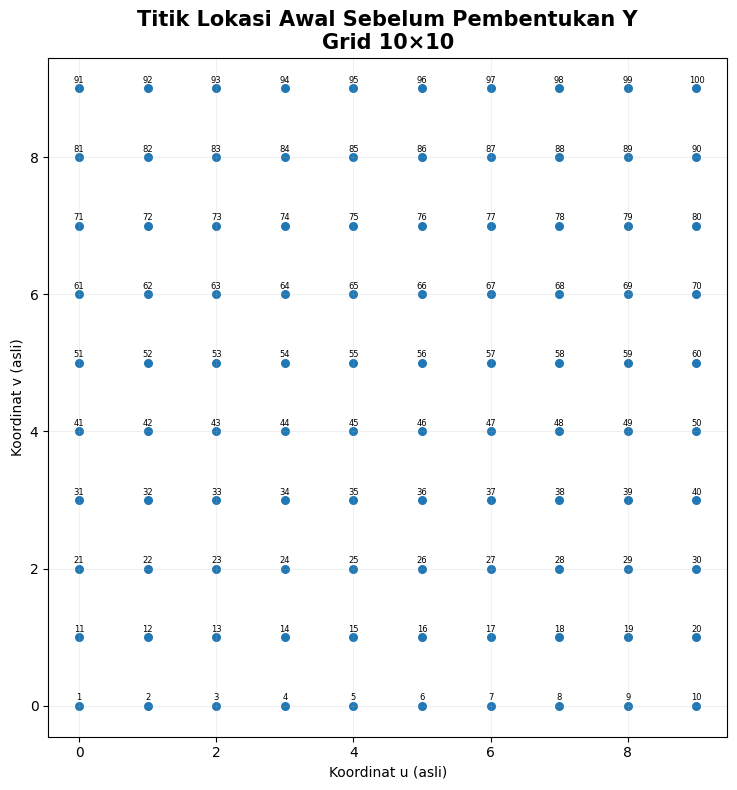

✅ B. Z(s) SELESAI


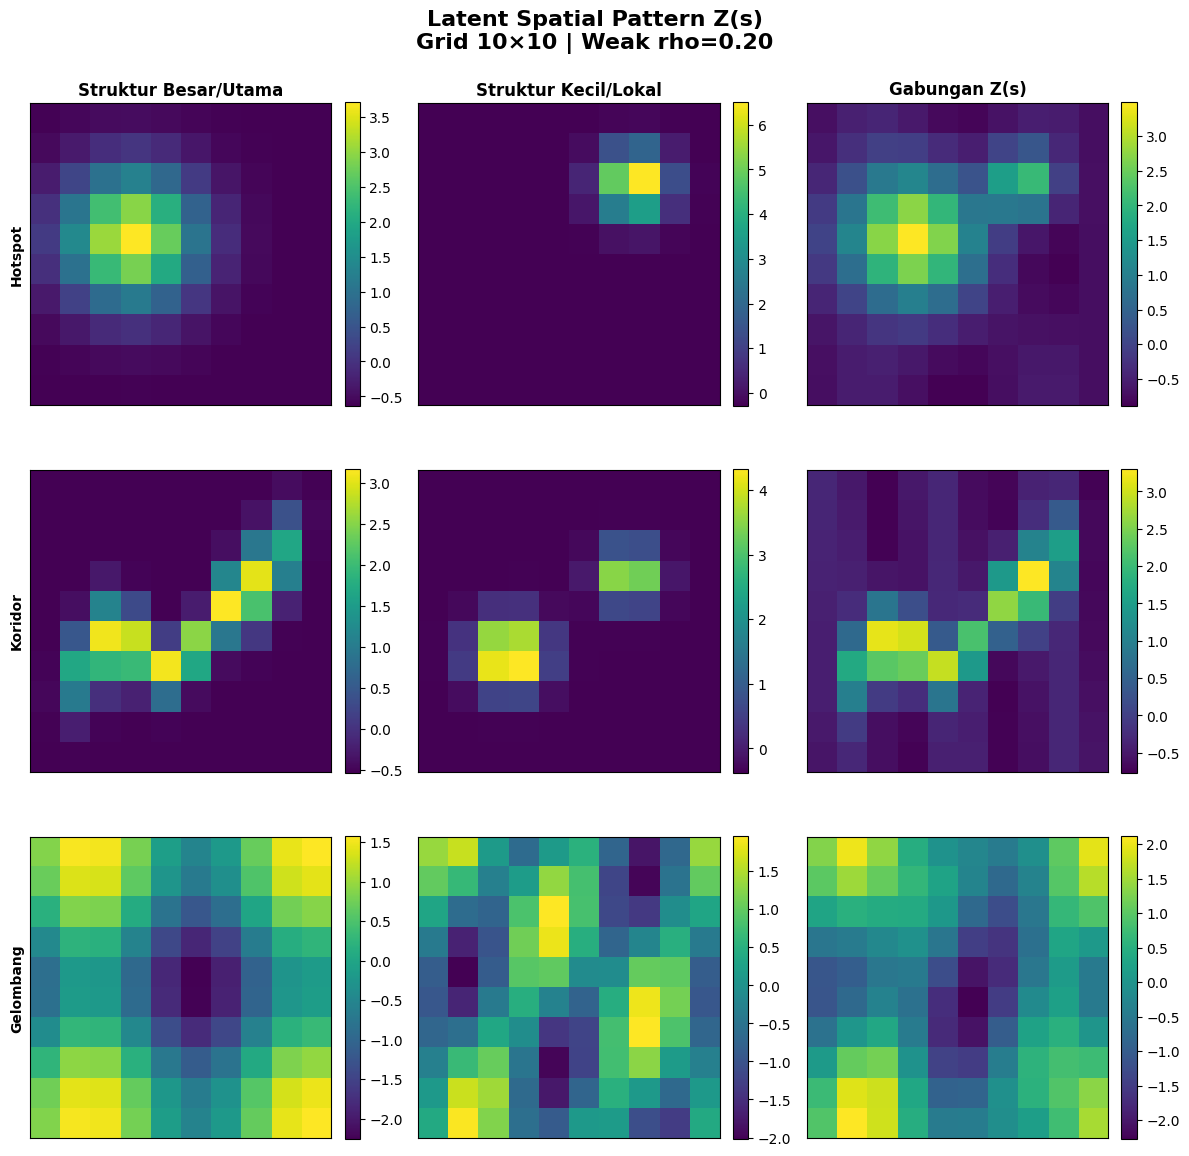

✅ C. X1, X2, X3 + g(X) SELESAI
   beta = (1.9778, -0.4720, 1.3086)
   SD g(X) setelah standardisasi = 1.0000


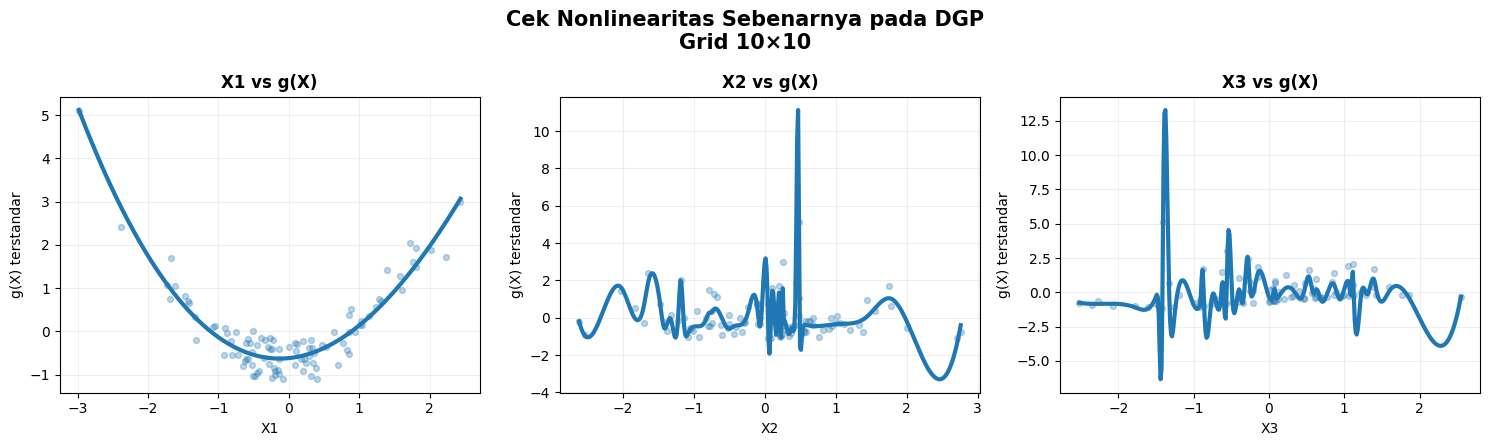

✅ D. W SELESAI


,Grid,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor
0,10x10,KNN5,5,5.00,5
1,10x10,DISTANCE,3,6.84,8
2,10x10,IDW,7,15.80,20


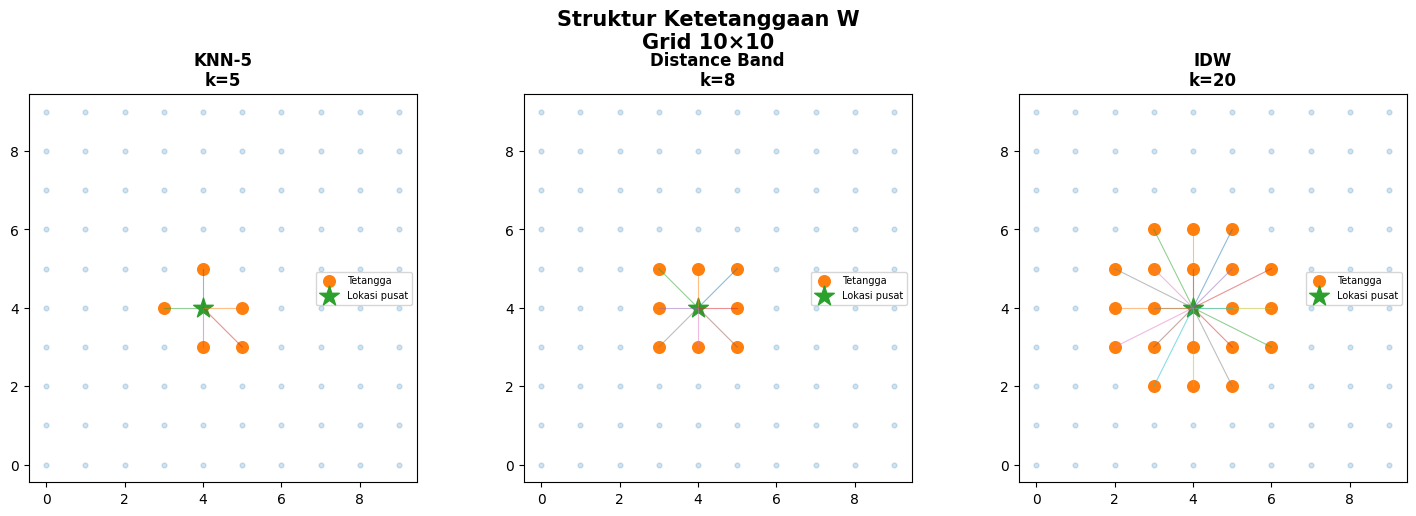

✅ E. 18 SKENARIO Y SELESAI


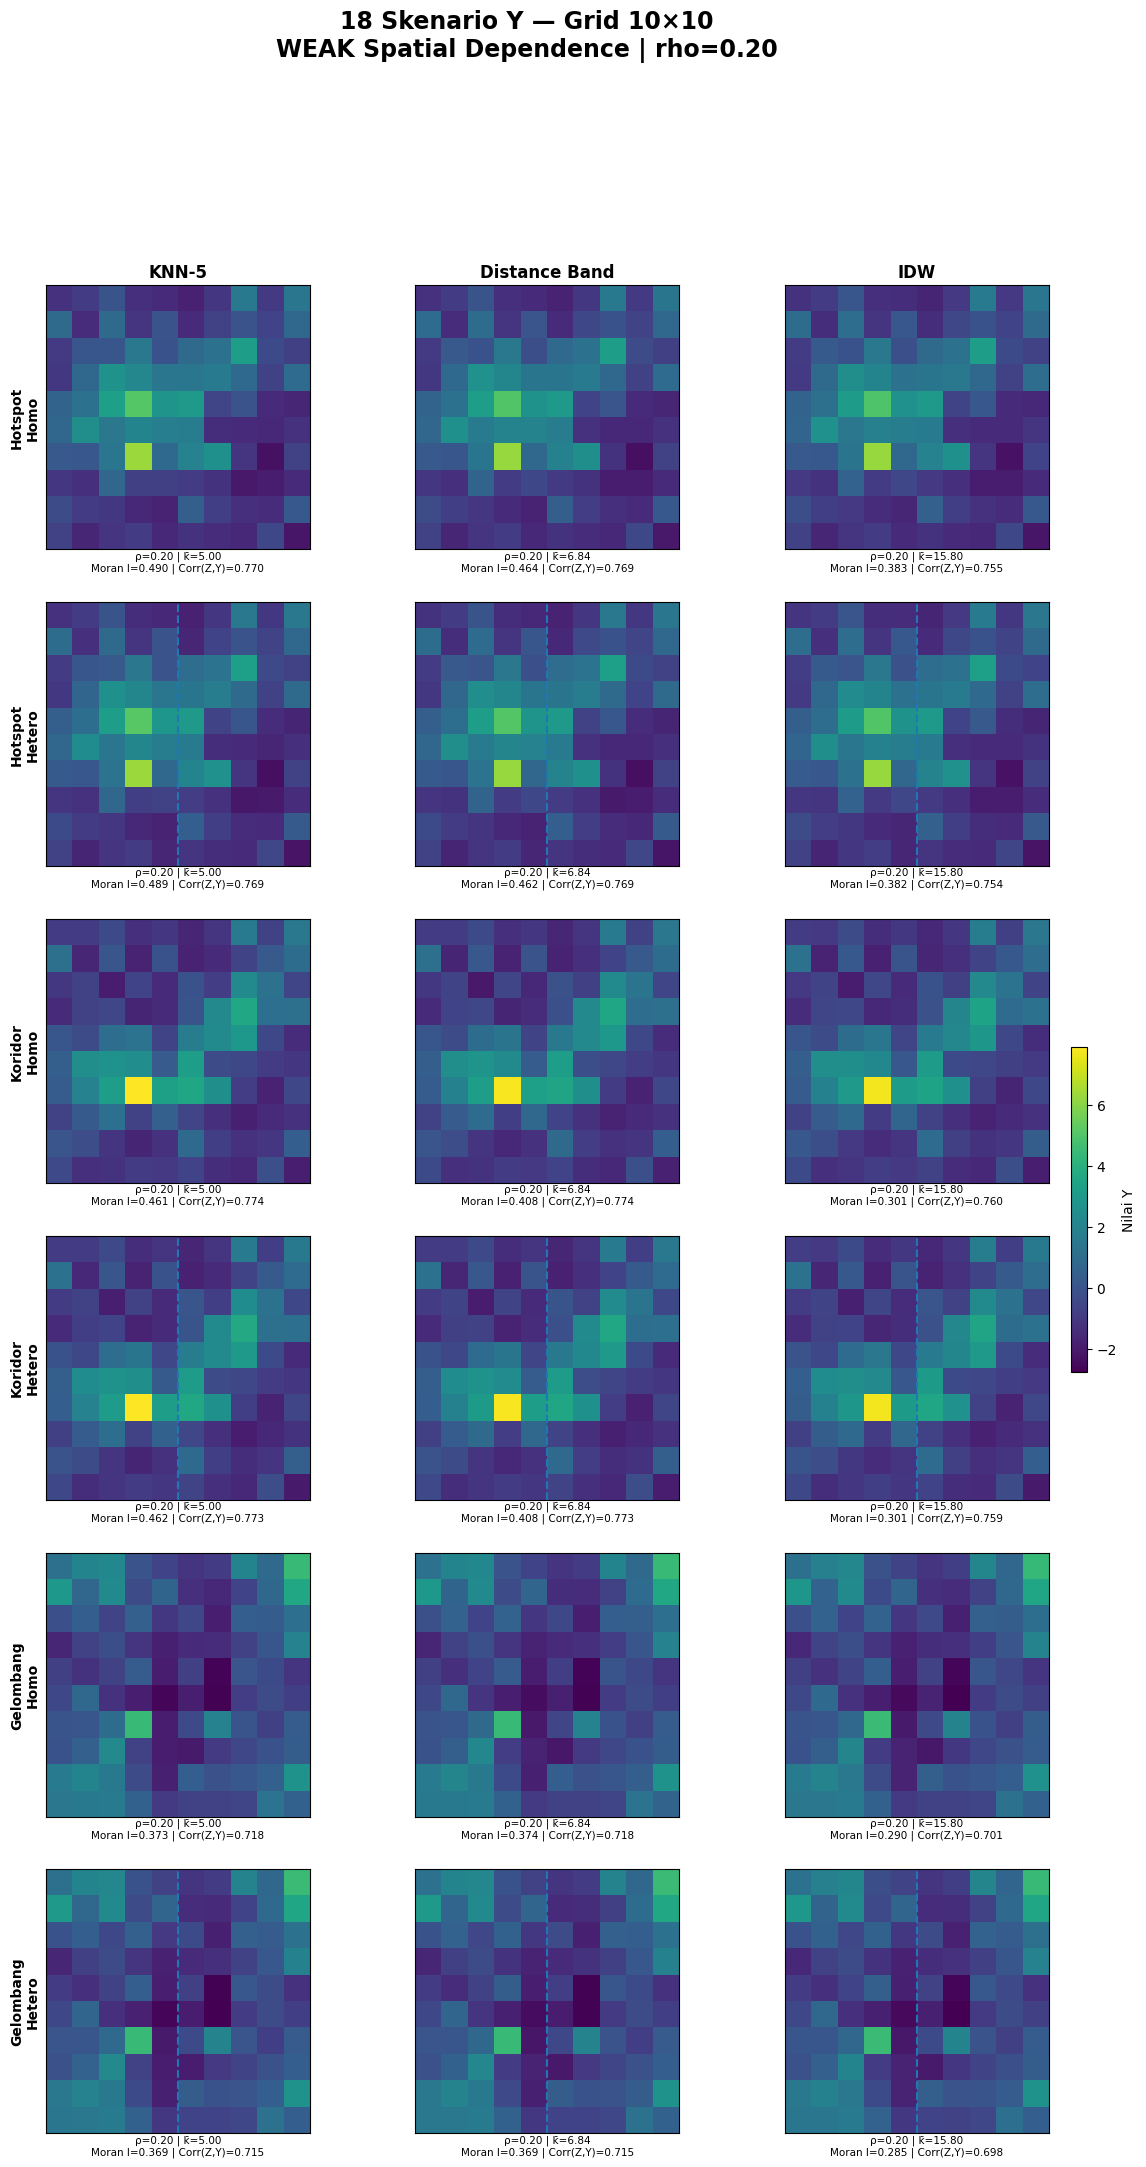

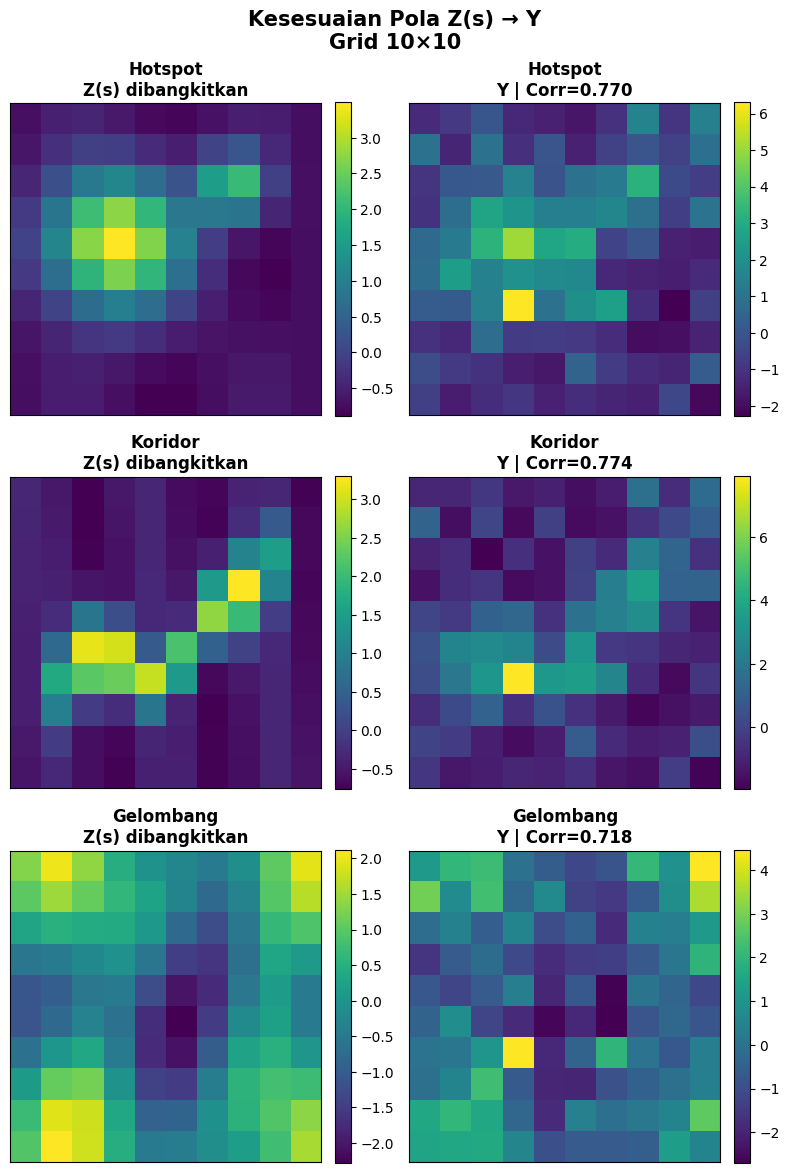

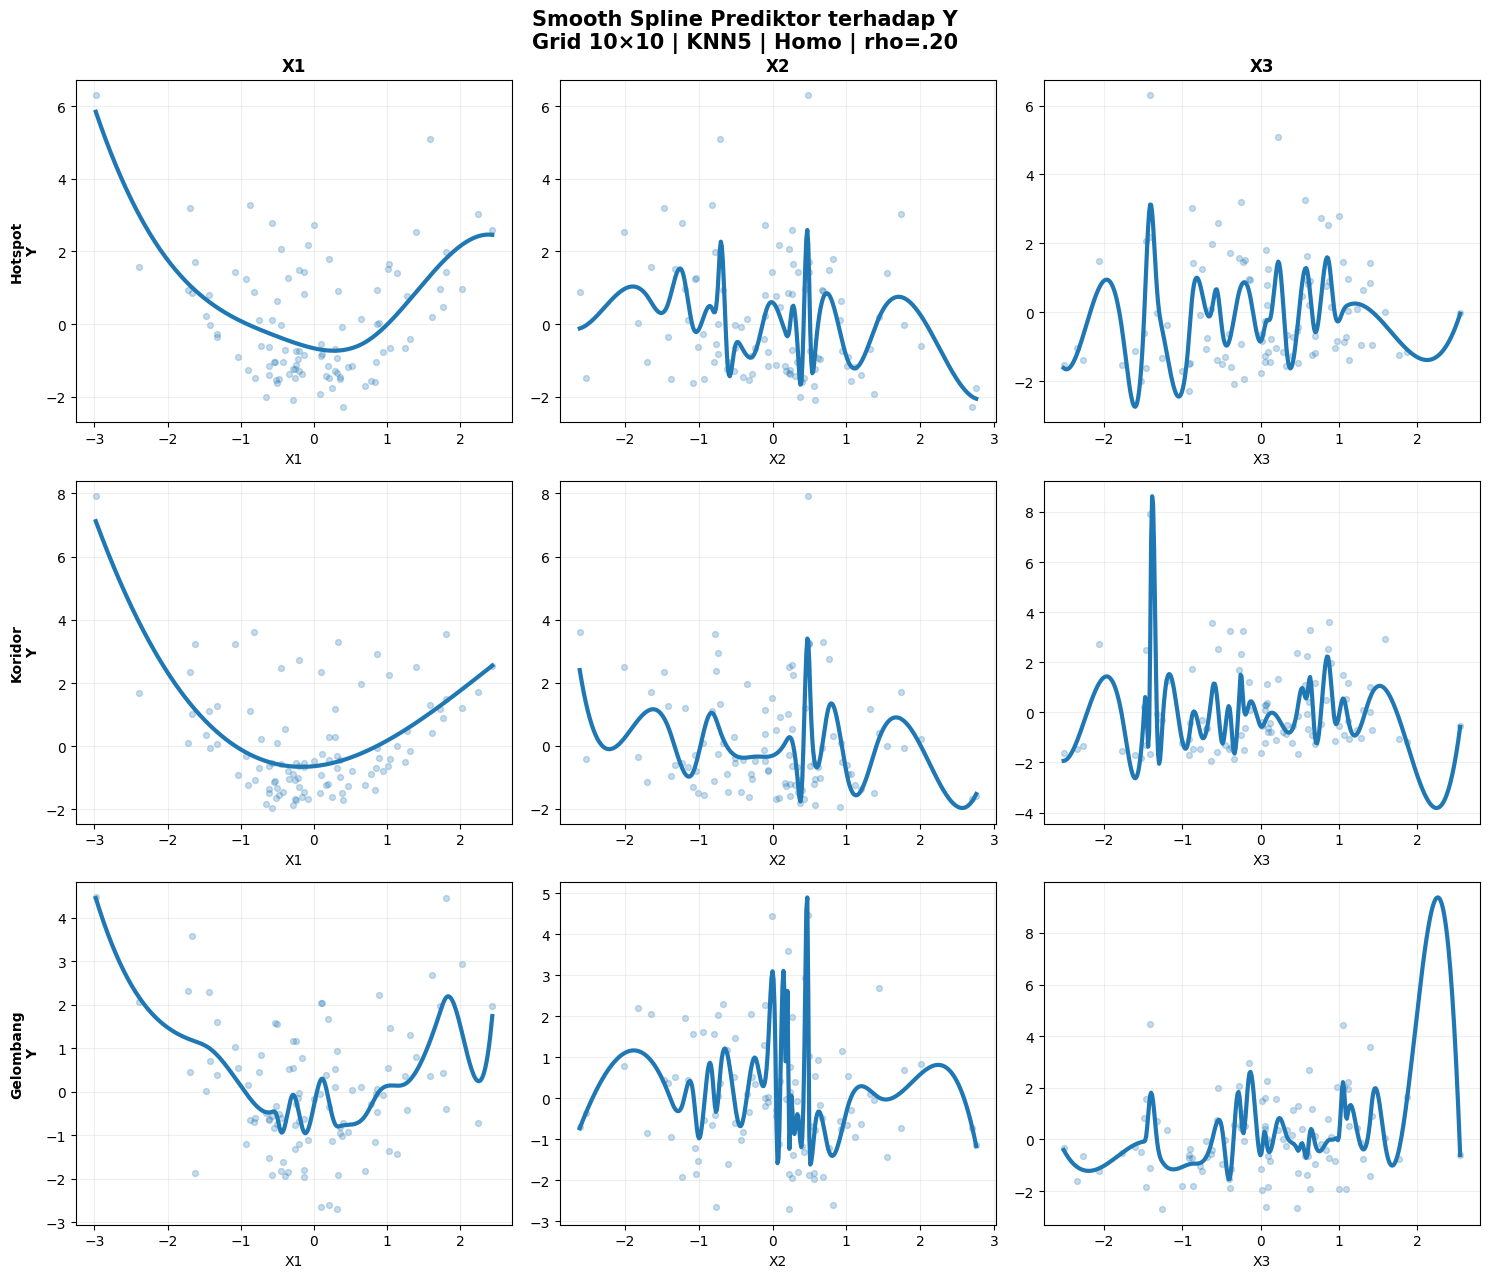



CEK BREUSCH-PAGAN — GRID 10×10 — WEAK rho=0.20:
  Pattern W_Method Error_Structure   BP_LM  BP_LM_pvalue    BP_F  BP_F_pvalue     BP_Expected     BP_Decision BP_Status
Gelombang DISTANCE   Heterogeneous 18.8247      0.000014 22.7264     0.000006 Heteroskedastik Heteroskedastik      PASS
Gelombang DISTANCE     Homogeneous  3.0051      0.083002  3.0363     0.084560   Homoskedastik   Homoskedastik      PASS
Gelombang      IDW   Heterogeneous 18.8247      0.000014 22.7264     0.000006 Heteroskedastik Heteroskedastik      PASS
Gelombang      IDW     Homogeneous  3.0051      0.083002  3.0363     0.084560   Homoskedastik   Homoskedastik      PASS
Gelombang     KNN5   Heterogeneous 18.8247      0.000014 22.7264     0.000006 Heteroskedastik Heteroskedastik      PASS
Gelombang     KNN5     Homogeneous  3.0051      0.083002  3.0363     0.084560   Homoskedastik   Homoskedastik      PASS
  Hotspot DISTANCE   Heterogeneous 18.8247      0.000014 22.7264     0.000006 Heteroskedastik Heteroskedastik 

In [ ]:
# ================================================================
# ================================================================
# JALANKAN GRID 10×10


WEAK_GRID10 = run_weak_grid(
    10
)



WEAK SPATIAL DEPENDENCE — rho=0.20
GRID 20 × 20
N = 400

✅ A. GRID / KOORDINAT BERHASIL


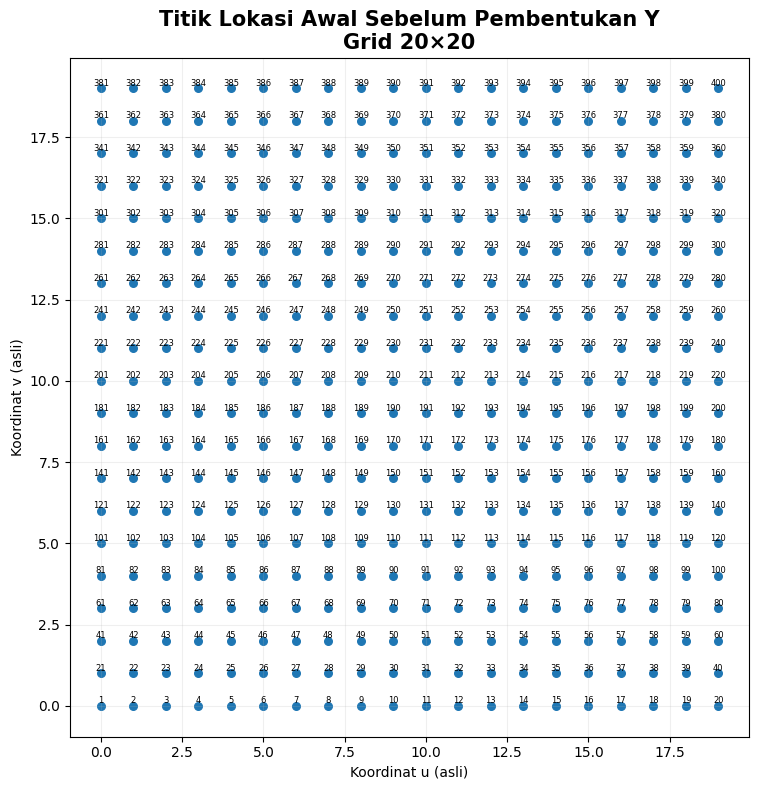

✅ B. Z(s) SELESAI


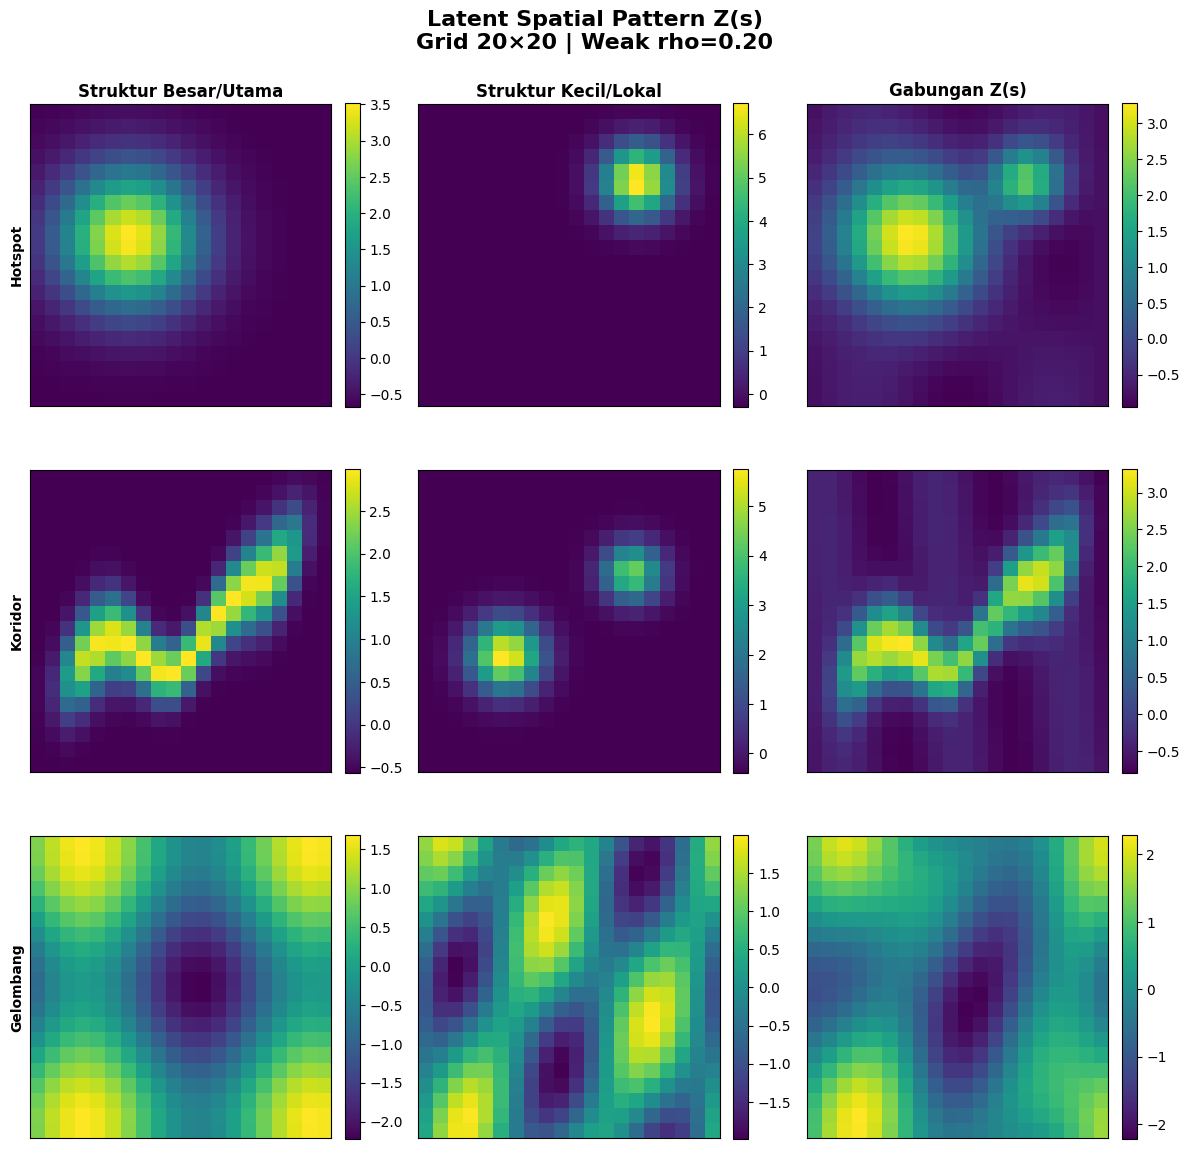

✅ C. X1, X2, X3 + g(X) SELESAI
   beta = (1.9778, -0.4720, 1.3086)
   SD g(X) setelah standardisasi = 1.0000


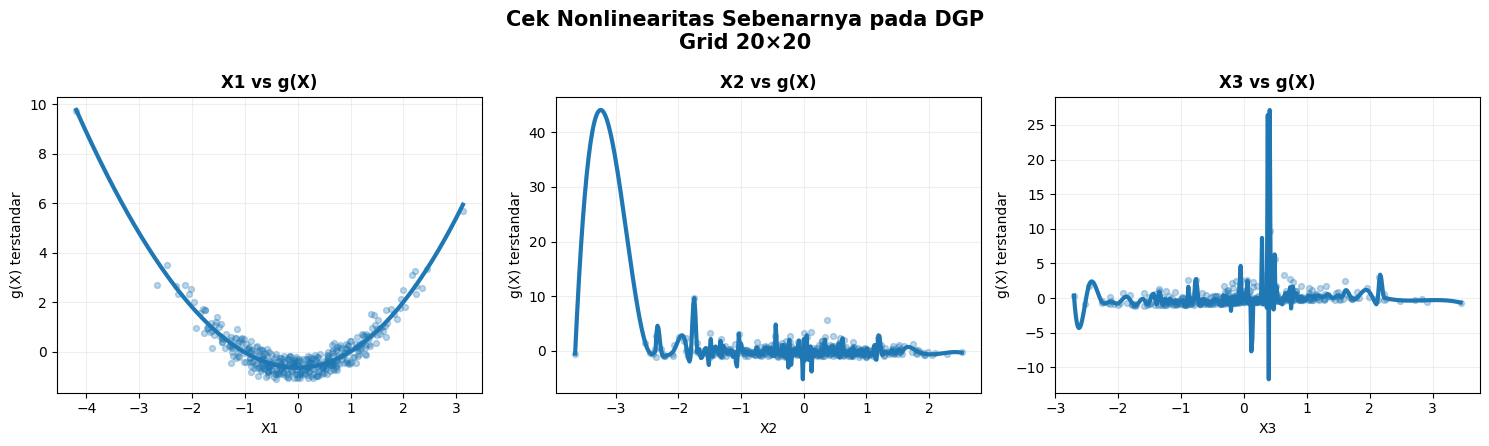

✅ D. W SELESAI


,Grid,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor
0,20x20,KNN5,5,5.00,5
1,20x20,DISTANCE,3,7.41,8
2,20x20,IDW,7,17.85,20


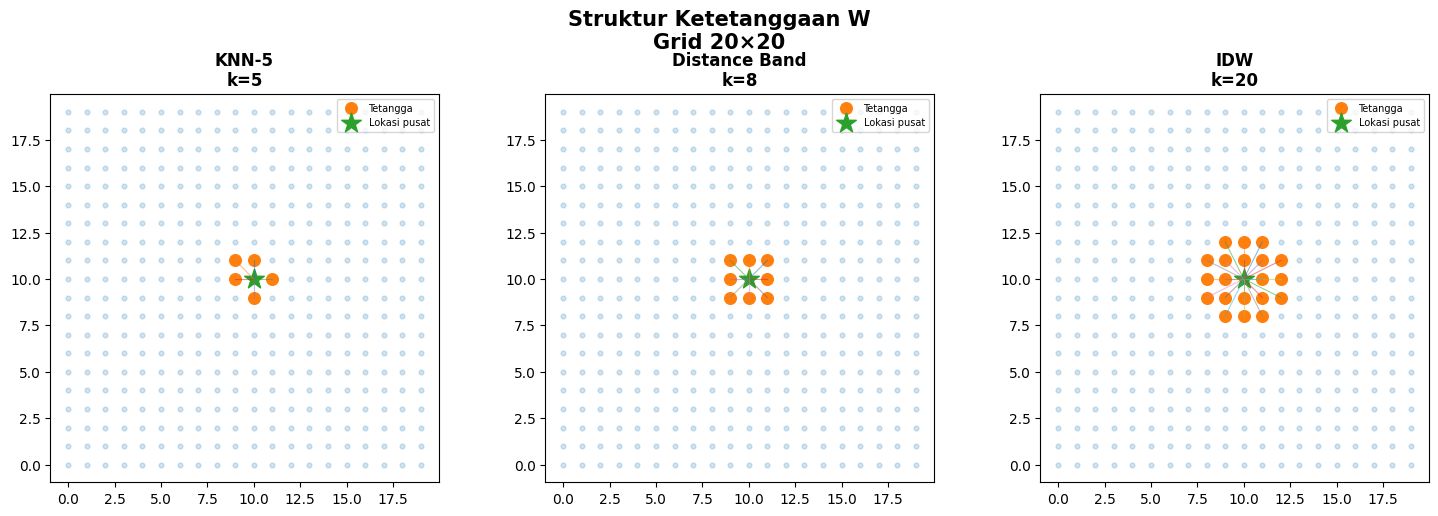

✅ E. 18 SKENARIO Y SELESAI


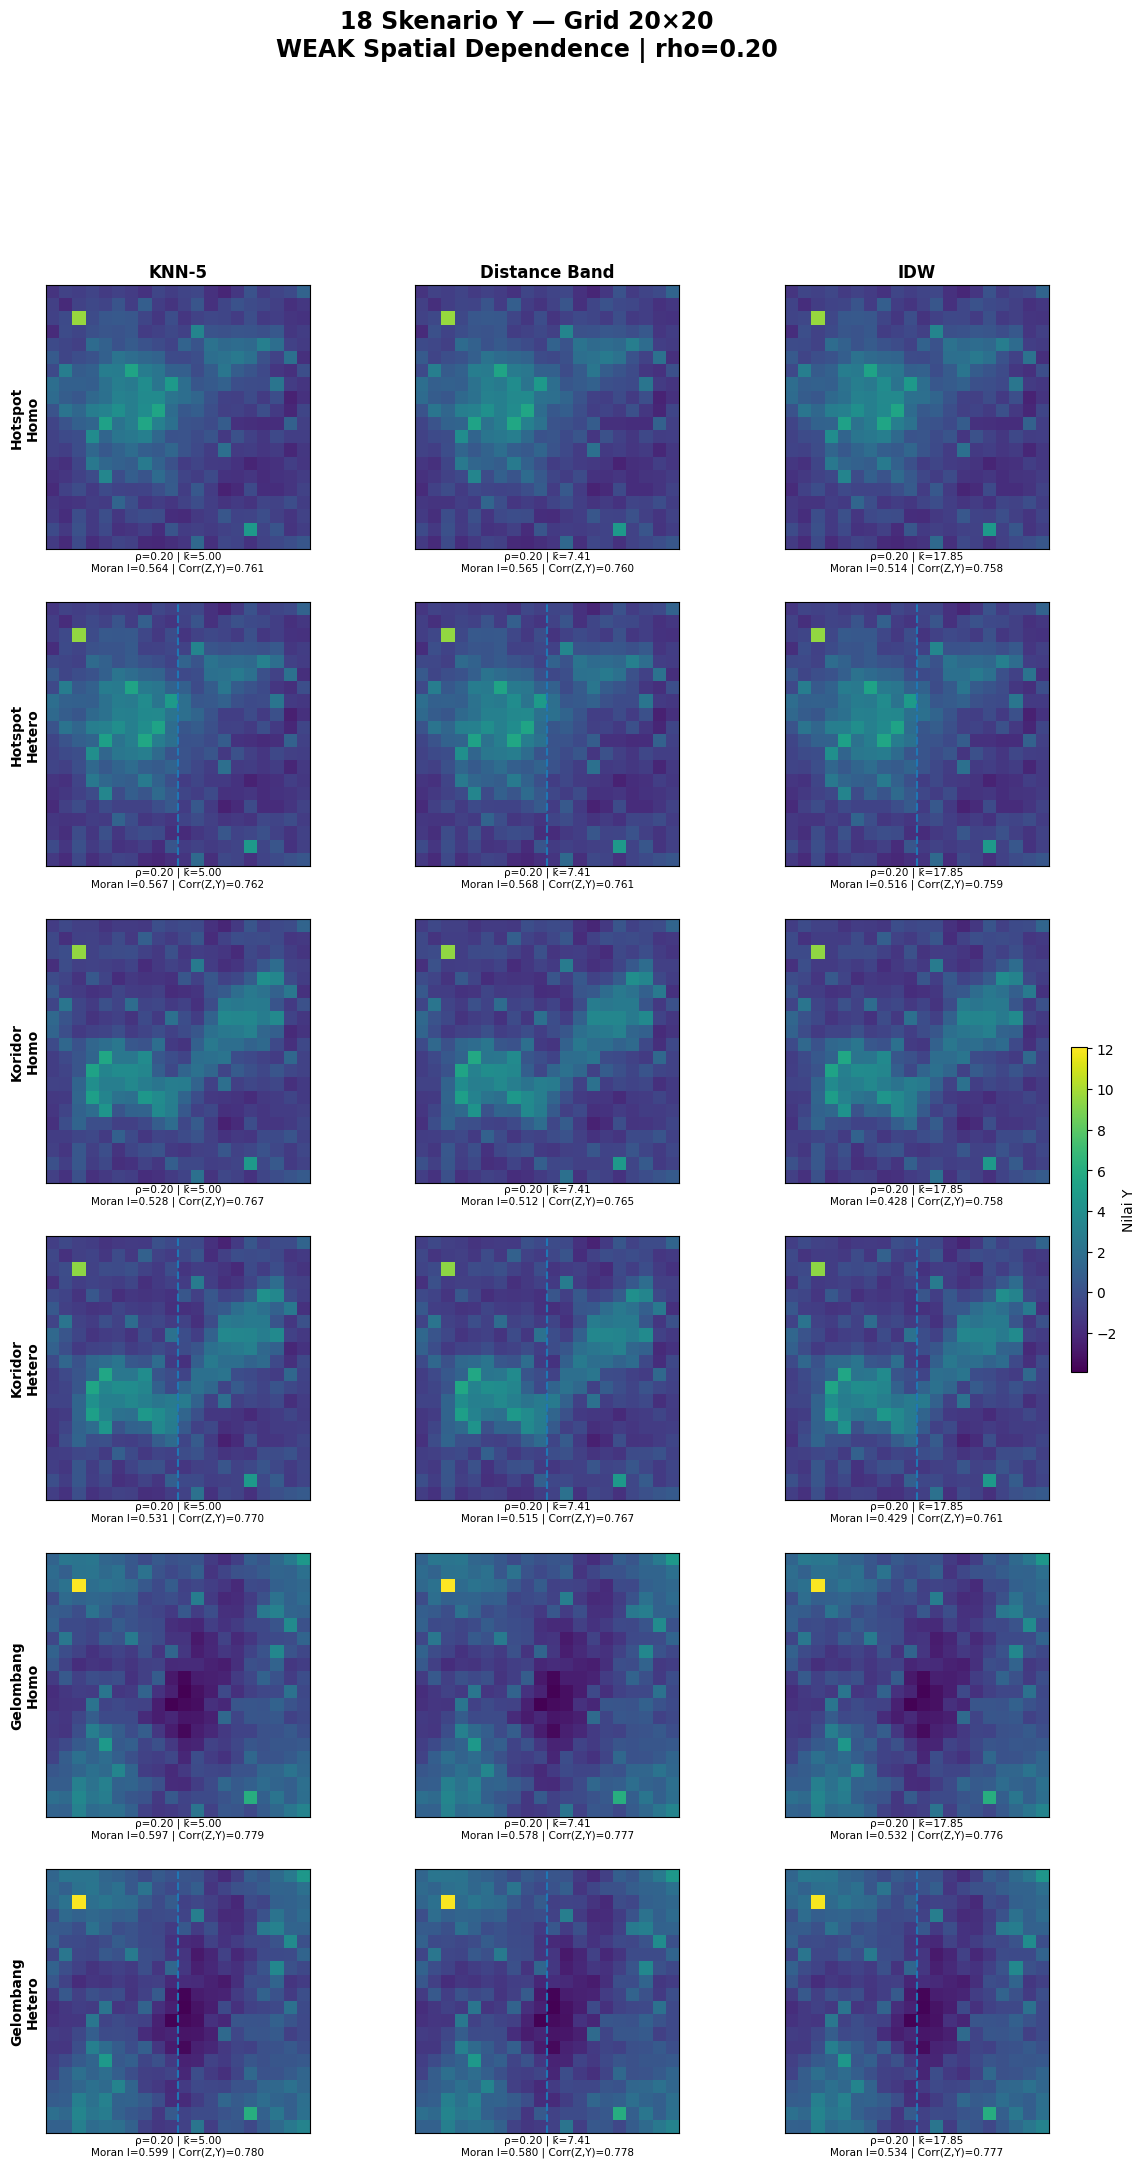

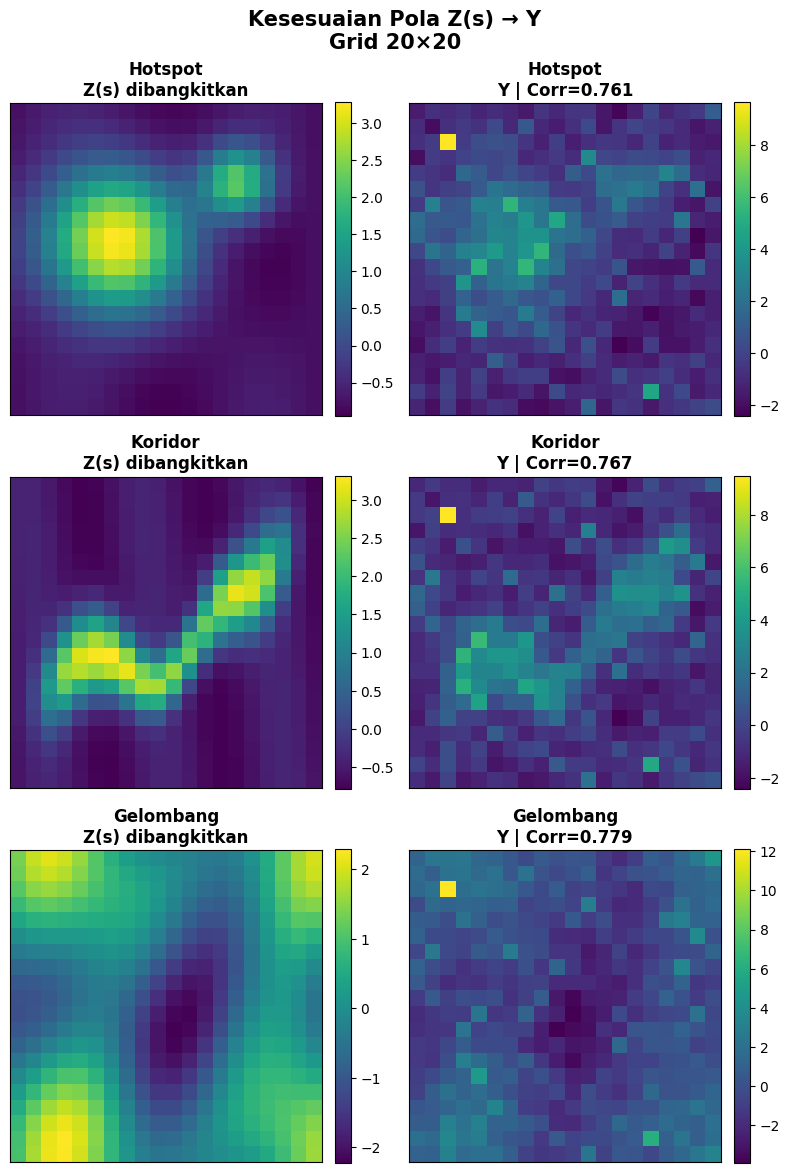

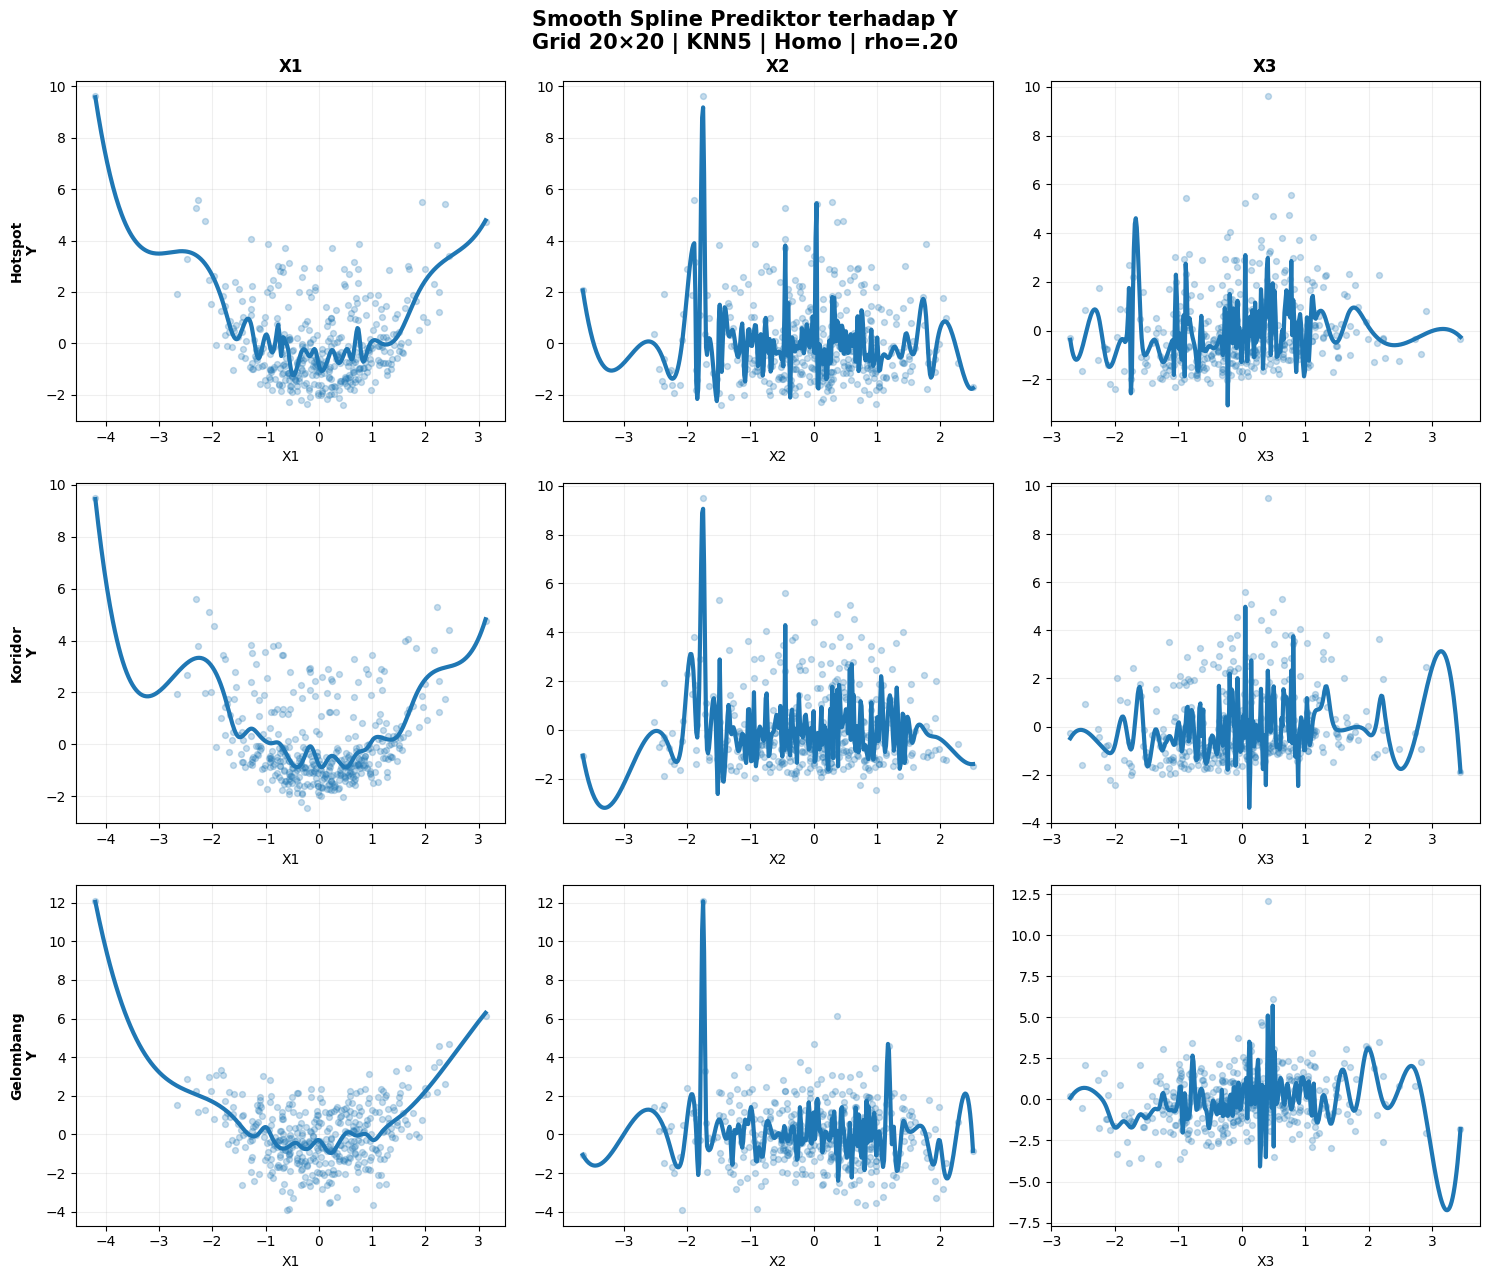



CEK BREUSCH-PAGAN — GRID 20×20 — WEAK rho=0.20:
  Pattern W_Method Error_Structure   BP_LM  BP_LM_pvalue    BP_F  BP_F_pvalue     BP_Expected     BP_Decision BP_Status
Gelombang DISTANCE   Heterogeneous 50.3429      0.000000 57.3032     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang DISTANCE     Homogeneous  1.1785      0.277655  1.1761     0.278807   Homoskedastik   Homoskedastik      PASS
Gelombang      IDW   Heterogeneous 50.3429      0.000000 57.3032     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang      IDW     Homogeneous  1.1785      0.277655  1.1761     0.278807   Homoskedastik   Homoskedastik      PASS
Gelombang     KNN5   Heterogeneous 50.3429      0.000000 57.3032     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang     KNN5     Homogeneous  1.1785      0.277655  1.1761     0.278807   Homoskedastik   Homoskedastik      PASS
  Hotspot DISTANCE   Heterogeneous 50.3429      0.000000 57.3032     0.000000 Heteroskedastik Heteroskedastik 

In [ ]:
# ================================================================
# FILE WEAK — rho = 0.20
# CELL 2 — GRID 20×20
#


WEAK_GRID20 = run_weak_grid(
    20
)



WEAK SPATIAL DEPENDENCE — rho=0.20
GRID 30 × 30
N = 900

✅ A. GRID / KOORDINAT BERHASIL


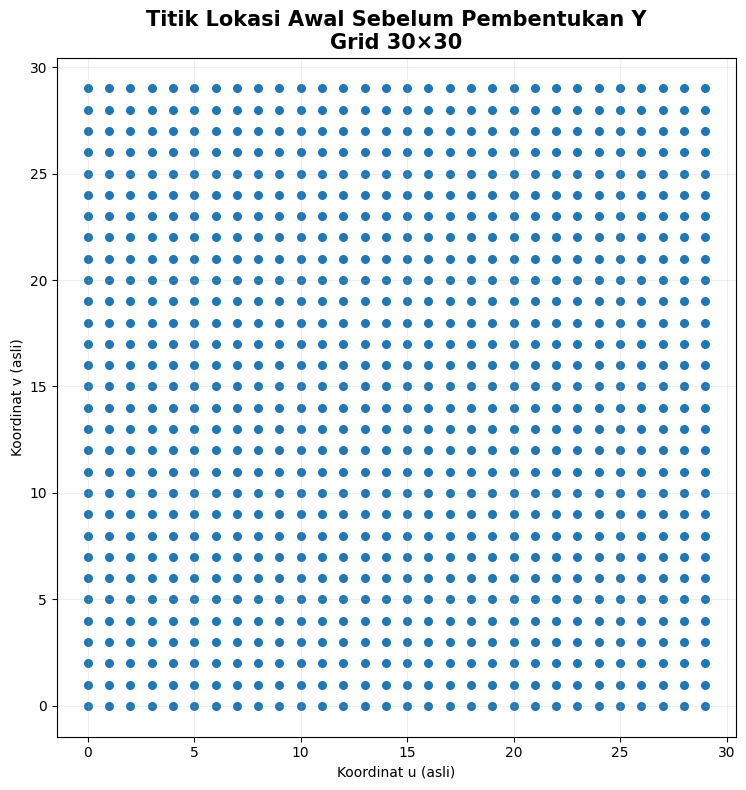

✅ B. Z(s) SELESAI


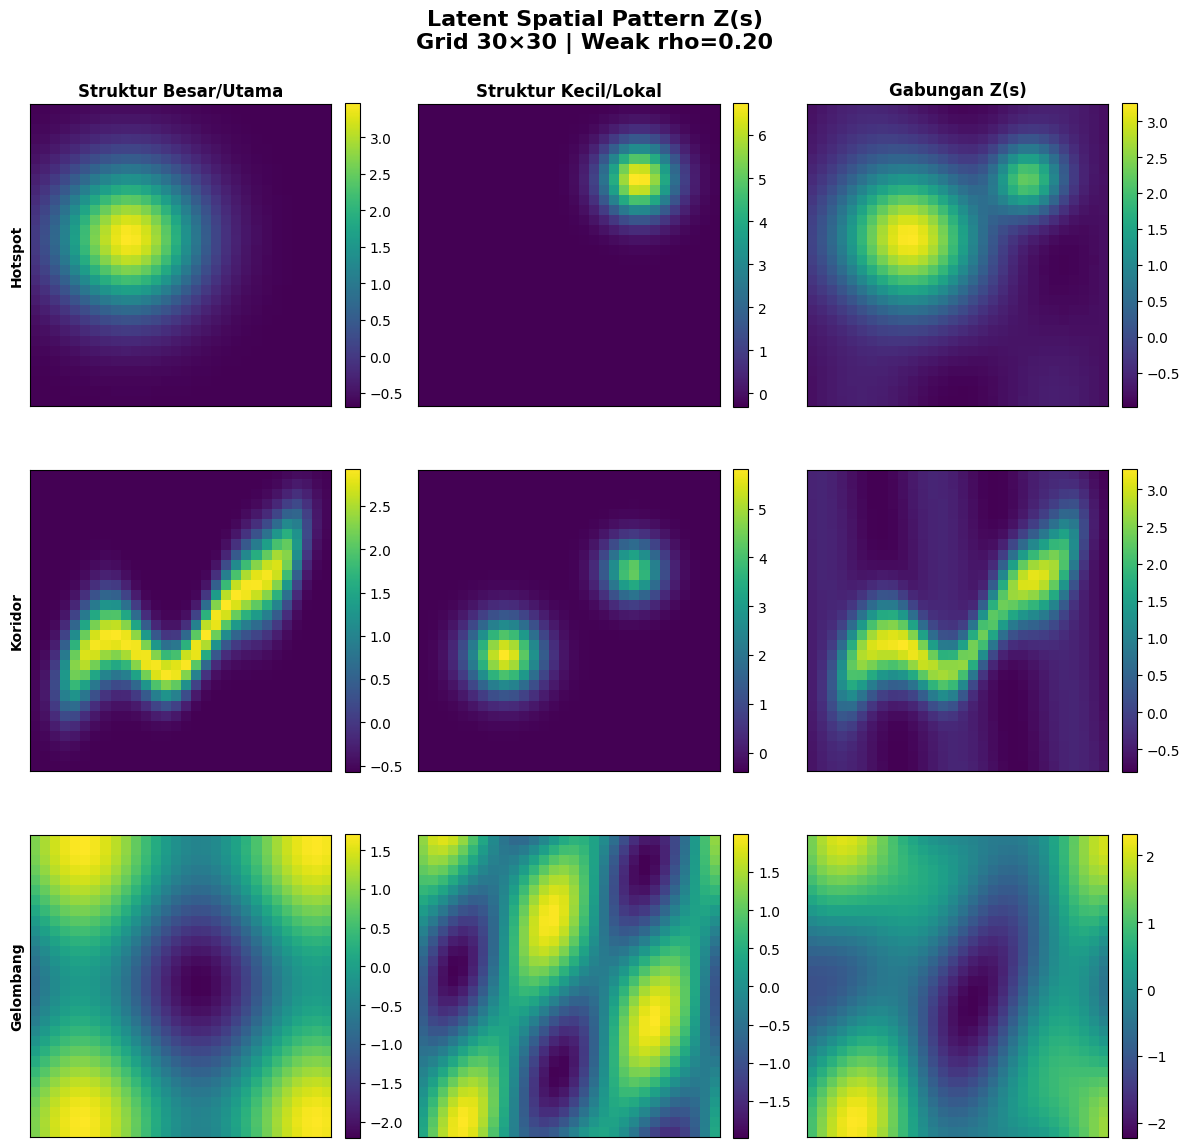

✅ C. X1, X2, X3 + g(X) SELESAI
   beta = (1.9778, -0.4720, 1.3086)
   SD g(X) setelah standardisasi = 1.0000


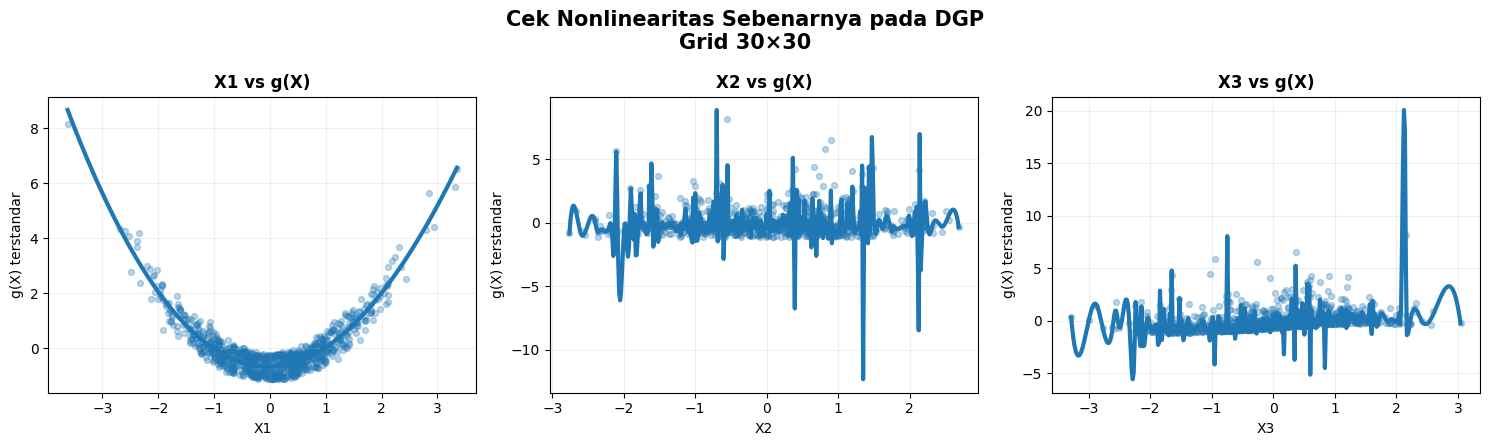

✅ D. W SELESAI


,Grid,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor
0,30x30,KNN5,5,5.00,5
1,30x30,DISTANCE,3,7.60,8
2,30x30,IDW,7,18.56,20


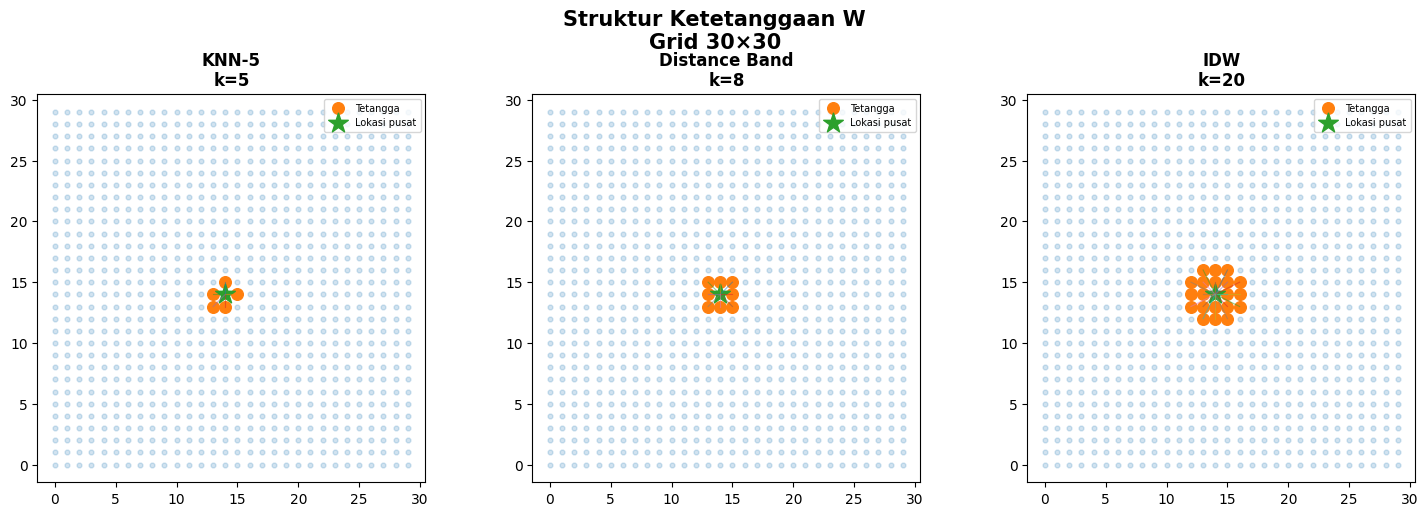

✅ E. 18 SKENARIO Y SELESAI


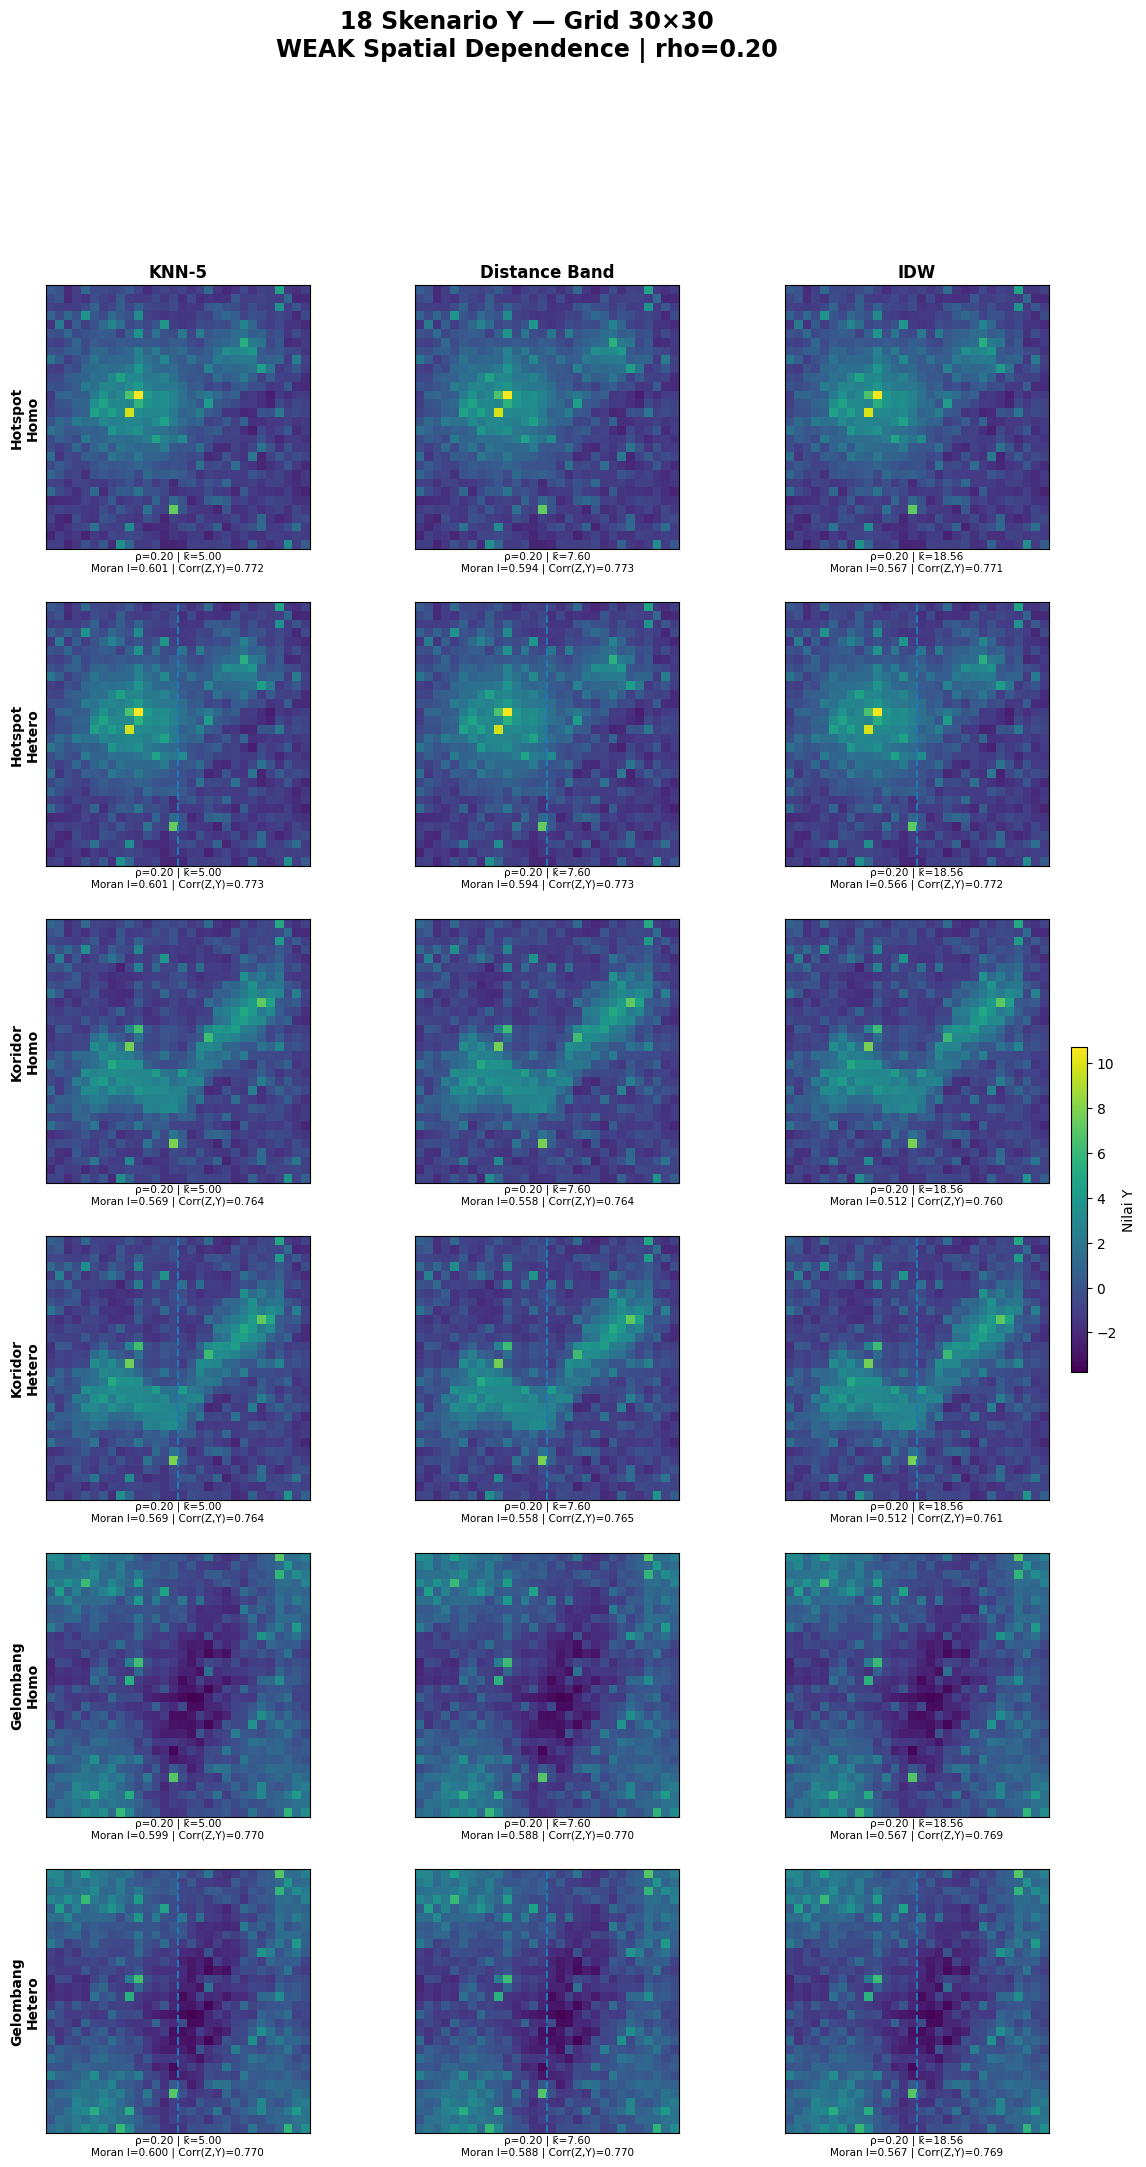

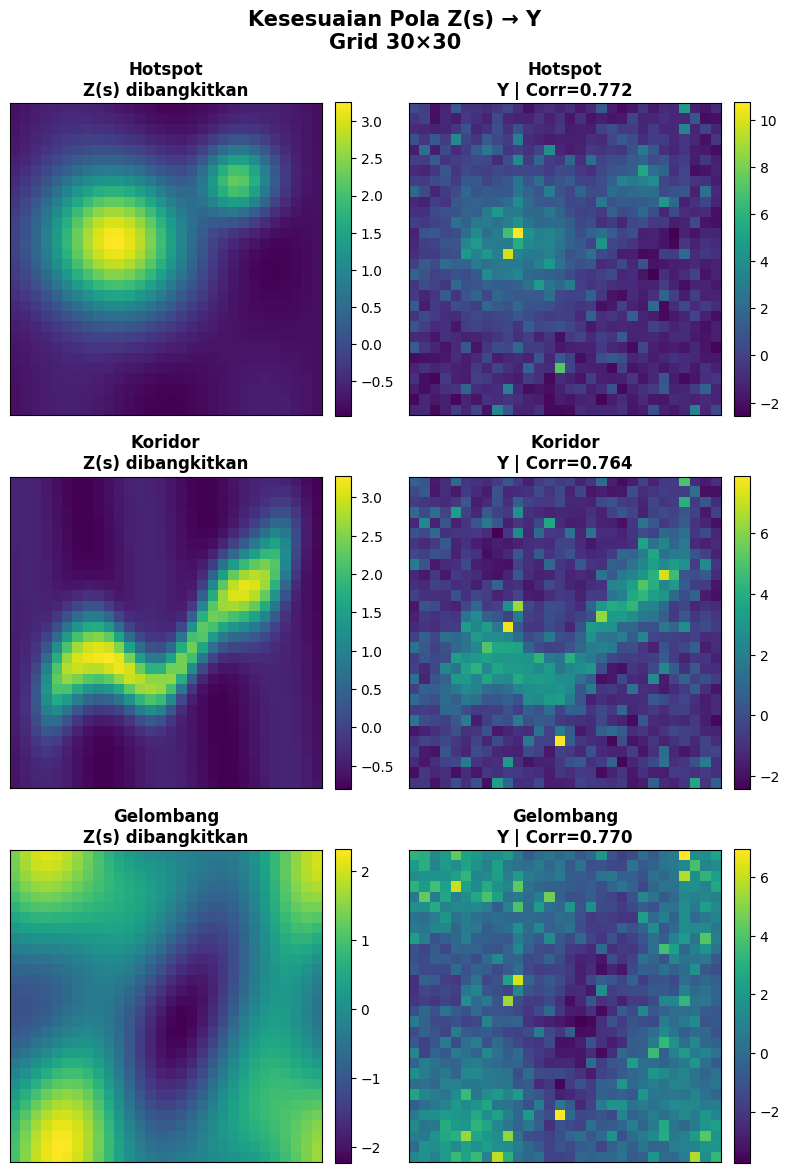

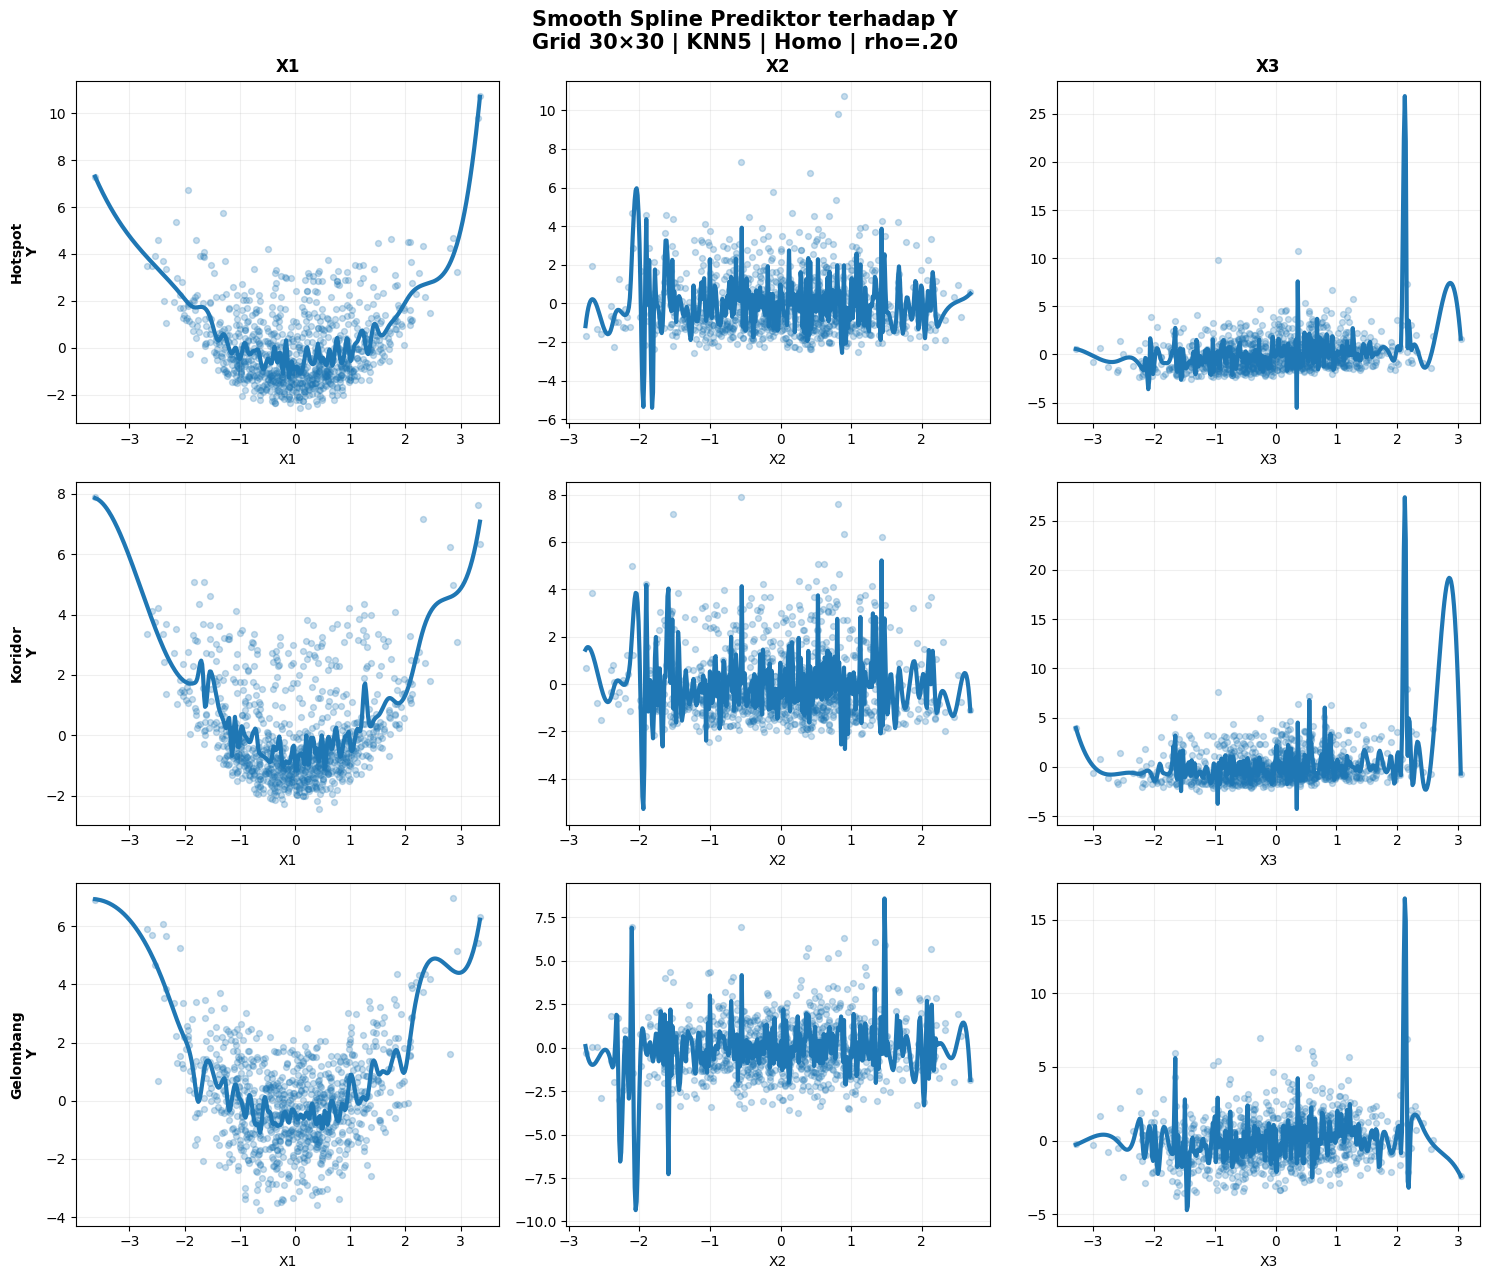



CEK BREUSCH-PAGAN — GRID 30×30 — WEAK rho=0.20:
  Pattern W_Method Error_Structure   BP_LM  BP_LM_pvalue     BP_F  BP_F_pvalue     BP_Expected     BP_Decision BP_Status
Gelombang DISTANCE   Heterogeneous 95.4304      0.000000 106.5122      0.00000 Heteroskedastik Heteroskedastik      PASS
Gelombang DISTANCE     Homogeneous  0.0929      0.760494   0.0927      0.76081   Homoskedastik   Homoskedastik      PASS
Gelombang      IDW   Heterogeneous 95.4304      0.000000 106.5122      0.00000 Heteroskedastik Heteroskedastik      PASS
Gelombang      IDW     Homogeneous  0.0929      0.760494   0.0927      0.76081   Homoskedastik   Homoskedastik      PASS
Gelombang     KNN5   Heterogeneous 95.4304      0.000000 106.5122      0.00000 Heteroskedastik Heteroskedastik      PASS
Gelombang     KNN5     Homogeneous  0.0929      0.760494   0.0927      0.76081   Homoskedastik   Homoskedastik      PASS
  Hotspot DISTANCE   Heterogeneous 95.4304      0.000000 106.5122      0.00000 Heteroskedastik Heterosk

In [ ]:
# ================================================================
# FILE WEAK — rho = 0.20
# CELL 3 — GRID 30×30
# ================================================================

WEAK_GRID30 = run_weak_grid(
    30
)



WEAK SPATIAL DEPENDENCE — rho=0.20
GRID 40 × 40
N = 1600

✅ A. GRID / KOORDINAT BERHASIL


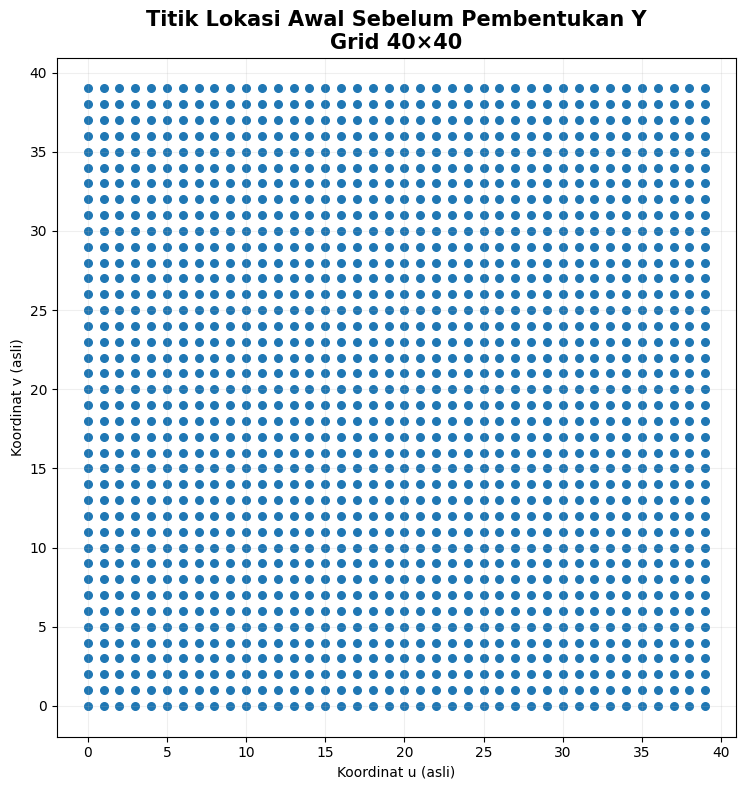

✅ B. Z(s) SELESAI


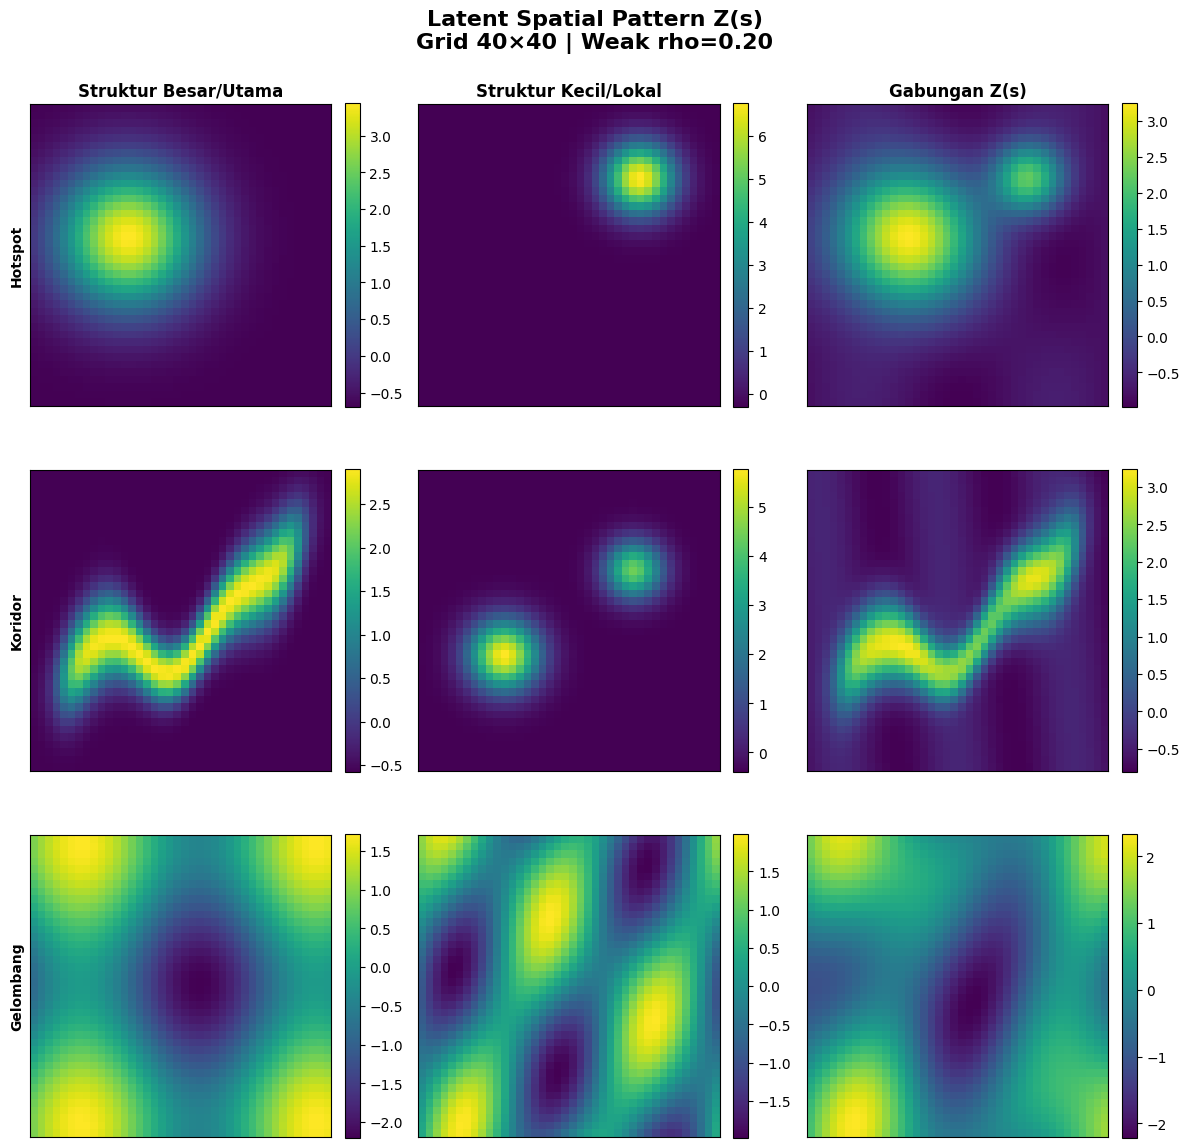

✅ C. X1, X2, X3 + g(X) SELESAI
   beta = (1.9778, -0.4720, 1.3086)
   SD g(X) setelah standardisasi = 1.0000


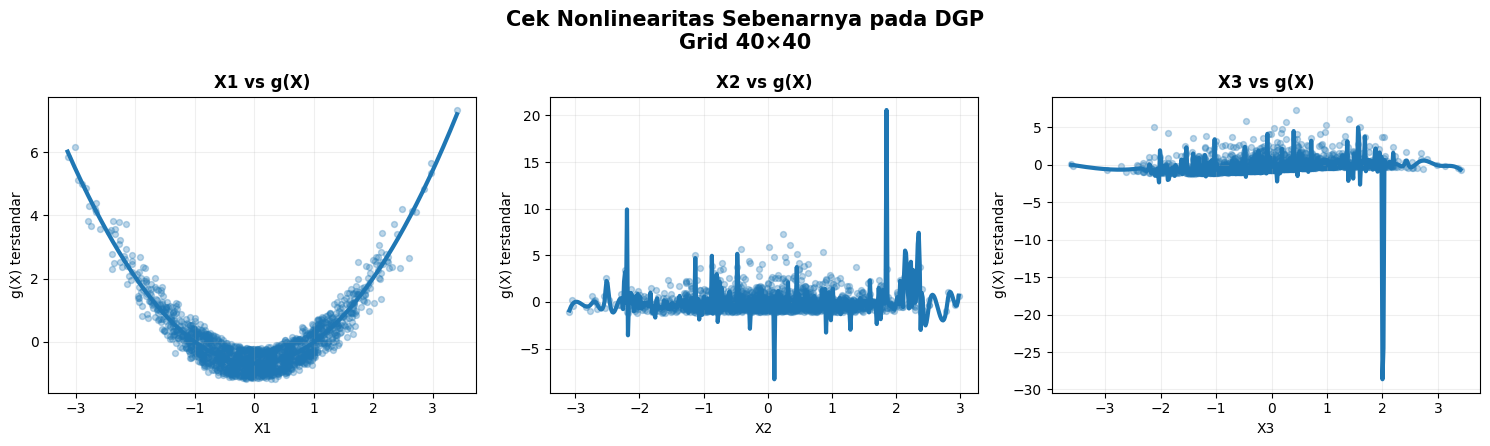

✅ D. W SELESAI


,Grid,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor
0,40x40,KNN5,5,5.00,5
1,40x40,DISTANCE,3,7.70,8
2,40x40,IDW,7,18.91,20


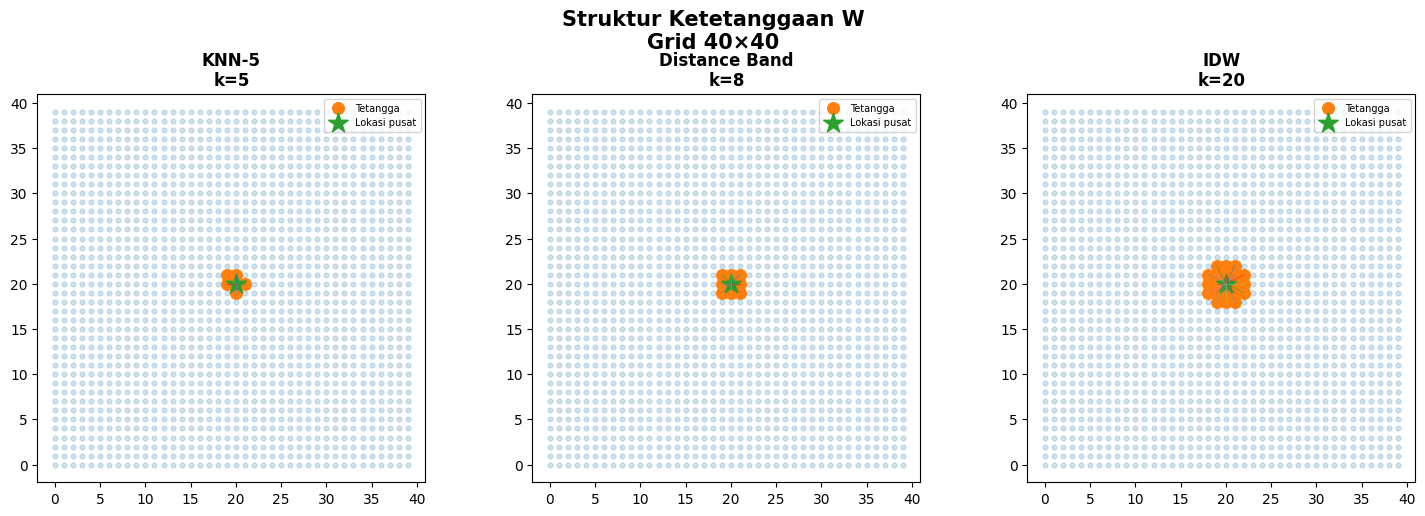

✅ E. 18 SKENARIO Y SELESAI


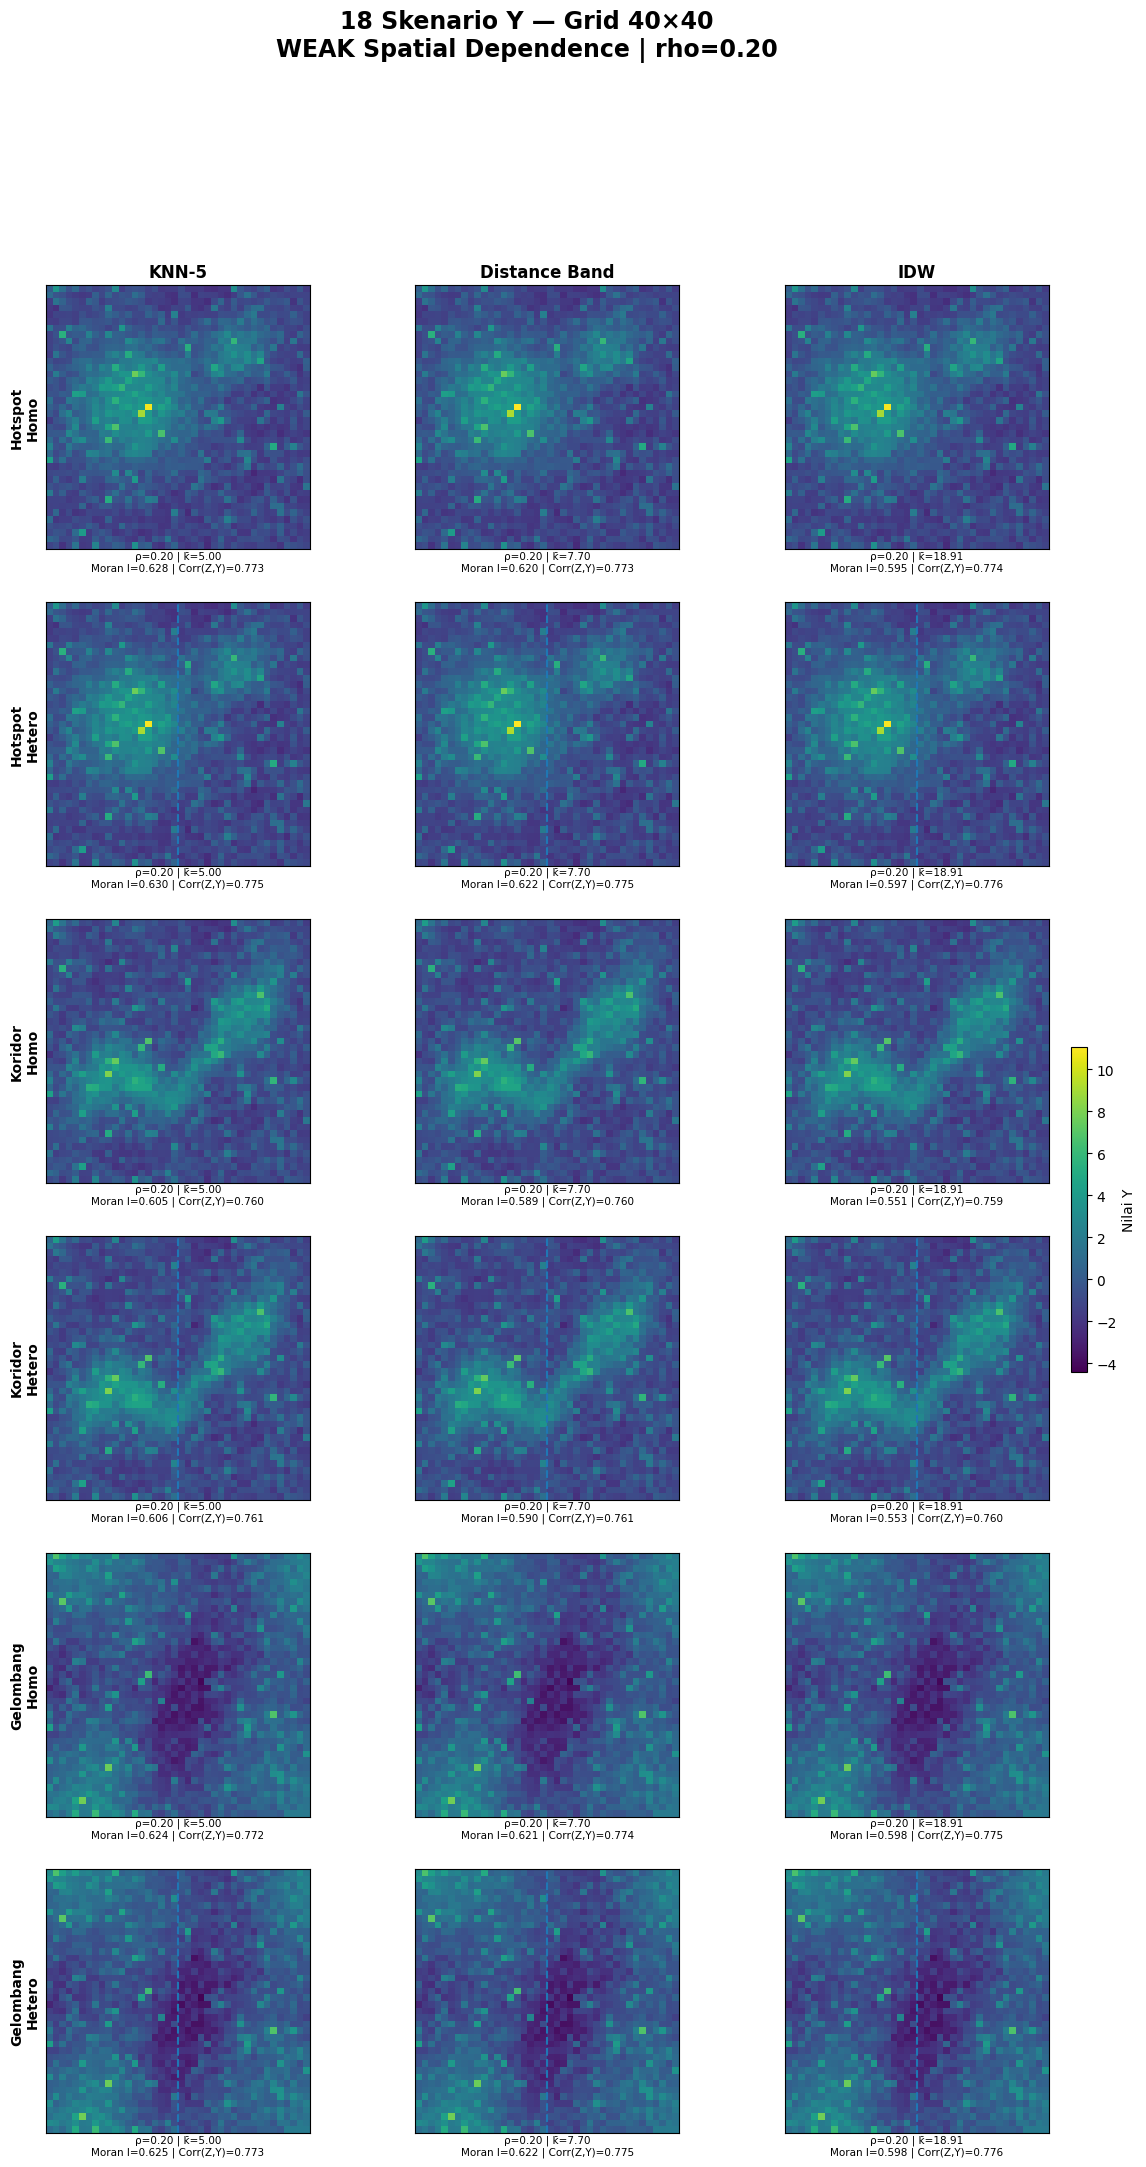

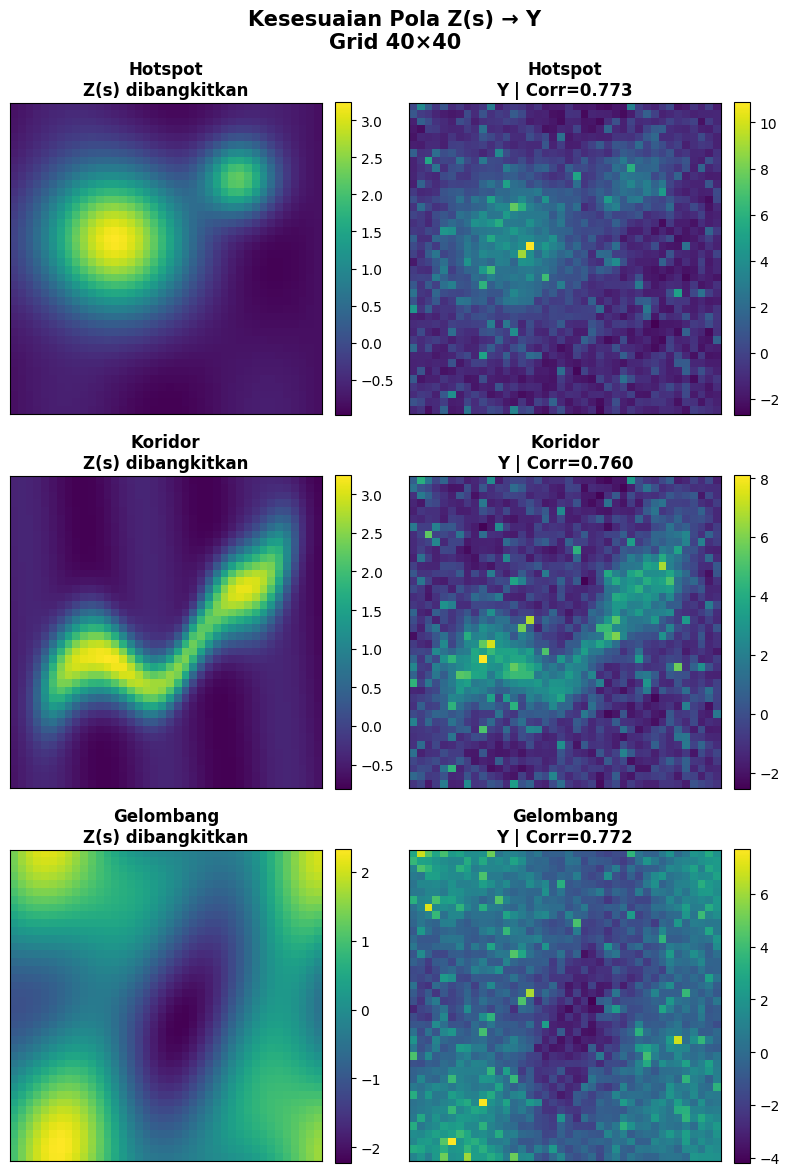

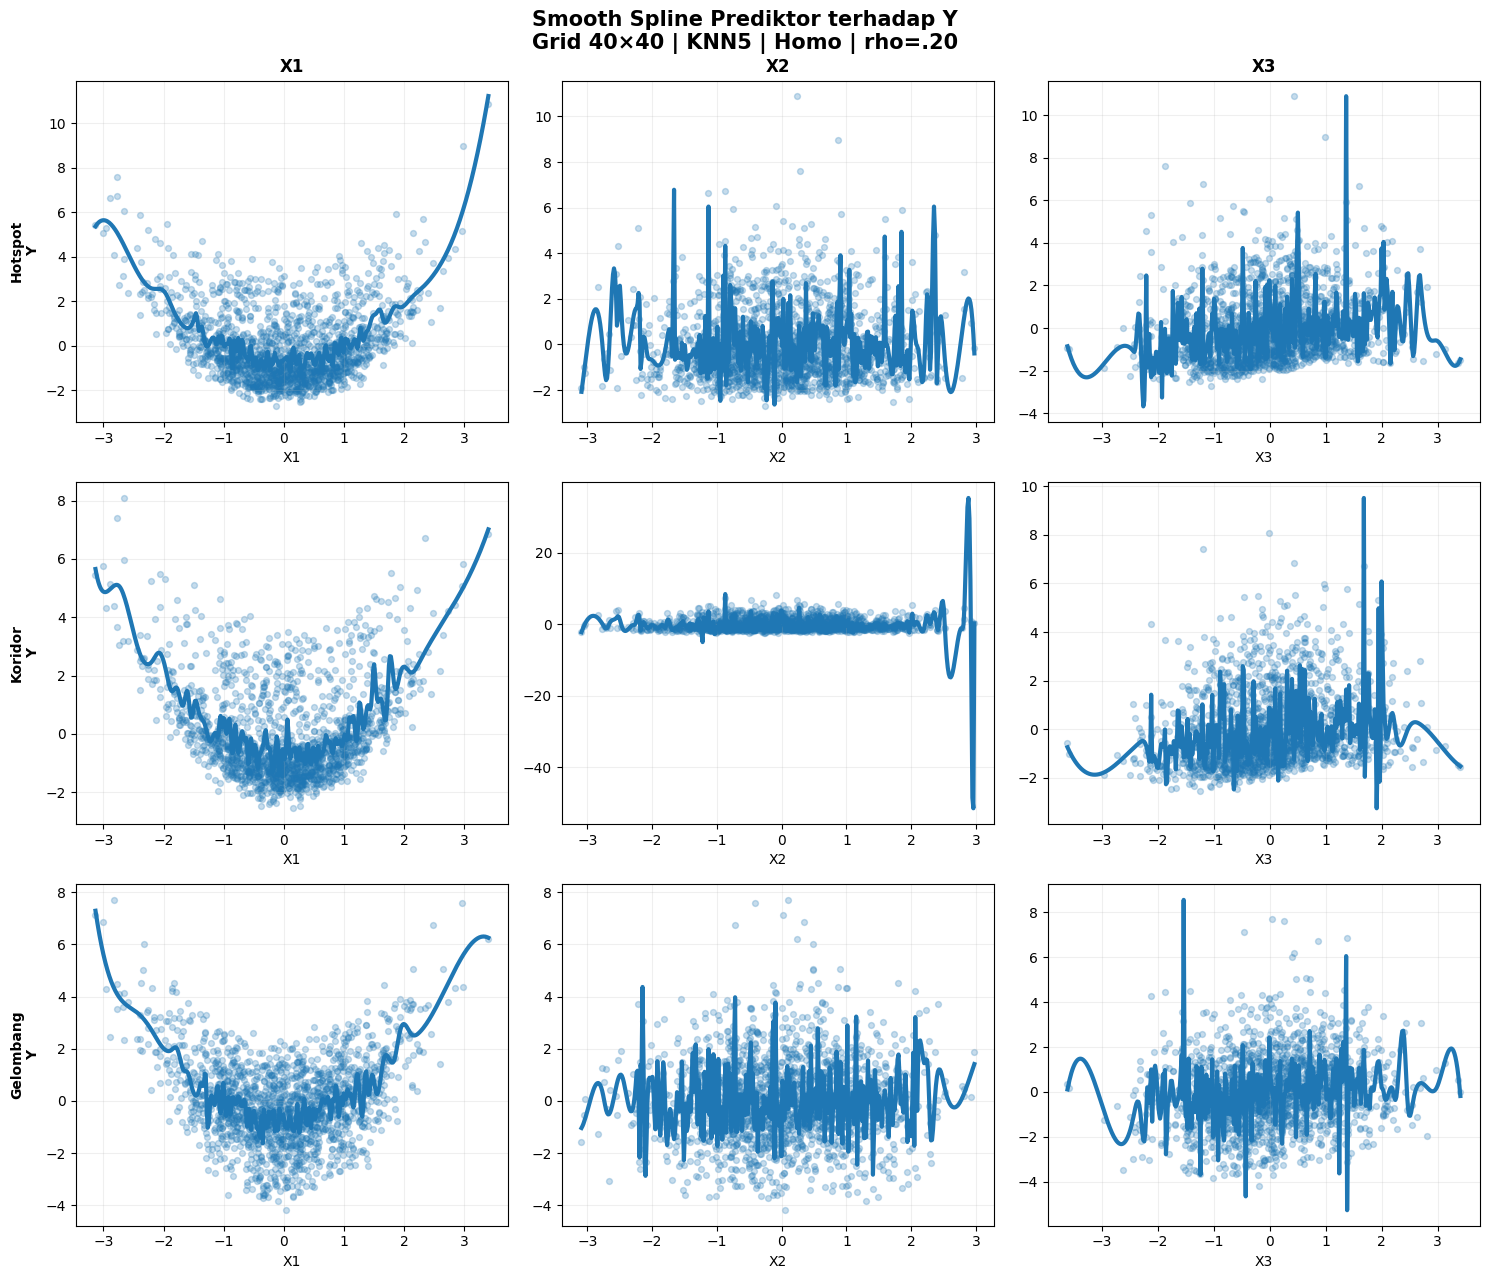



CEK BREUSCH-PAGAN — GRID 40×40 — WEAK rho=0.20:
  Pattern W_Method Error_Structure    BP_LM  BP_LM_pvalue     BP_F  BP_F_pvalue     BP_Expected     BP_Decision BP_Status
Gelombang DISTANCE   Heterogeneous 136.8095      0.000000 149.4142     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang DISTANCE     Homogeneous   0.0630      0.801772   0.0630     0.801922   Homoskedastik   Homoskedastik      PASS
Gelombang      IDW   Heterogeneous 136.8095      0.000000 149.4142     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang      IDW     Homogeneous   0.0630      0.801772   0.0630     0.801922   Homoskedastik   Homoskedastik      PASS
Gelombang     KNN5   Heterogeneous 136.8095      0.000000 149.4142     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang     KNN5     Homogeneous   0.0630      0.801772   0.0630     0.801922   Homoskedastik   Homoskedastik      PASS
  Hotspot DISTANCE   Heterogeneous 136.8095      0.000000 149.4142     0.000000 Heteroskedastik 

In [ ]:
# ================================================================
# FILE WEAK — rho = 0.20
# CELL 4 — GRID 40×40
# ================================================================

WEAK_GRID40 = run_weak_grid(
    40
)



WEAK SPATIAL DEPENDENCE — rho=0.20
GRID 50 × 50
N = 2500

✅ A. GRID / KOORDINAT BERHASIL


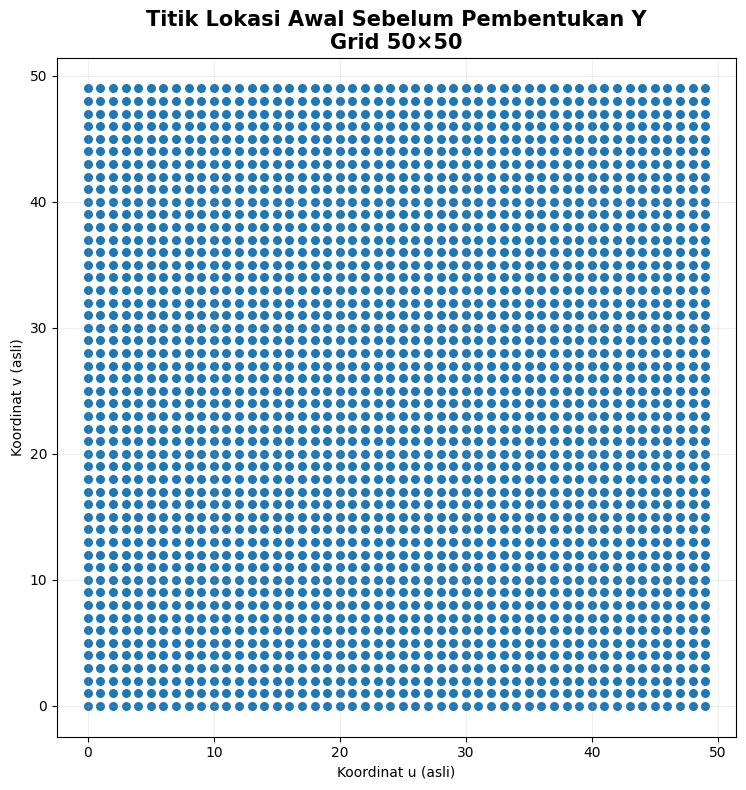

✅ B. Z(s) SELESAI


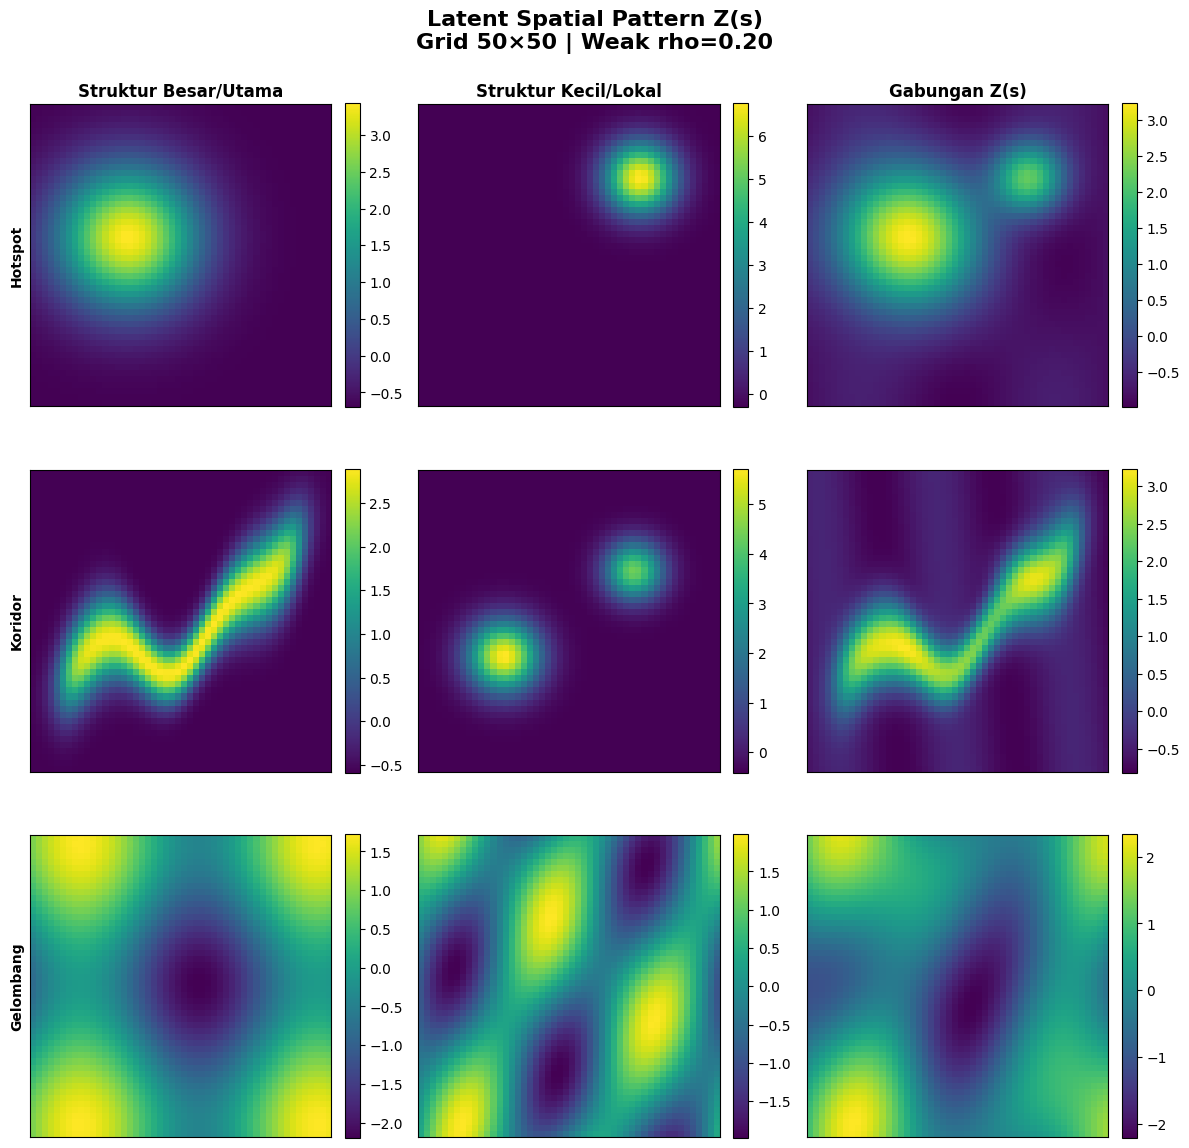

✅ C. X1, X2, X3 + g(X) SELESAI
   beta = (1.9778, -0.4720, 1.3086)
   SD g(X) setelah standardisasi = 1.0000


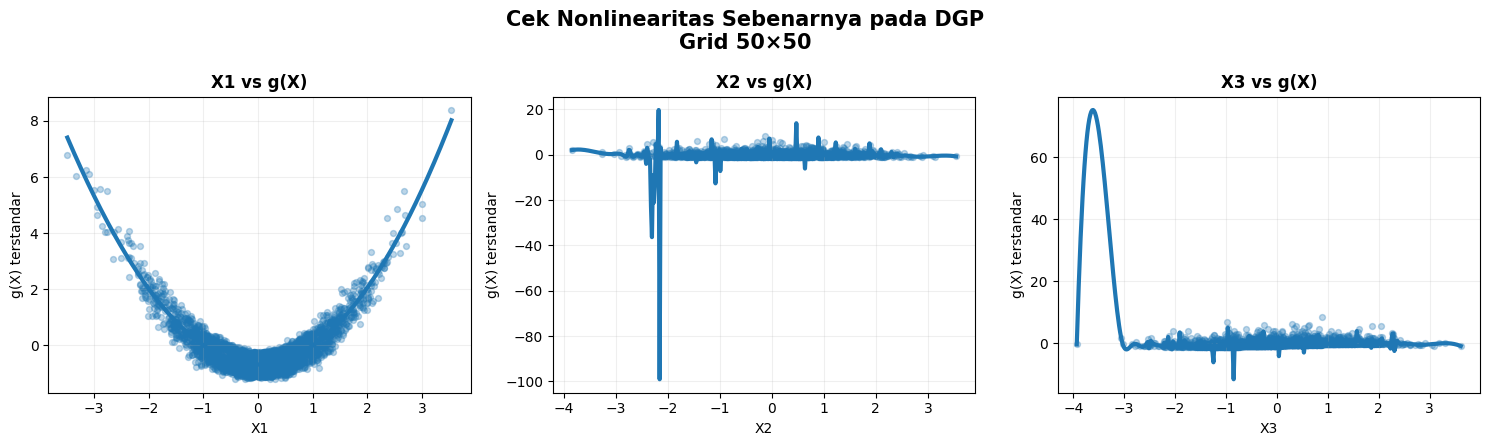

✅ D. W SELESAI


,Grid,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor
0,50x50,KNN5,5,5.00,5
1,50x50,DISTANCE,3,7.76,8
2,50x50,IDW,7,19.13,20


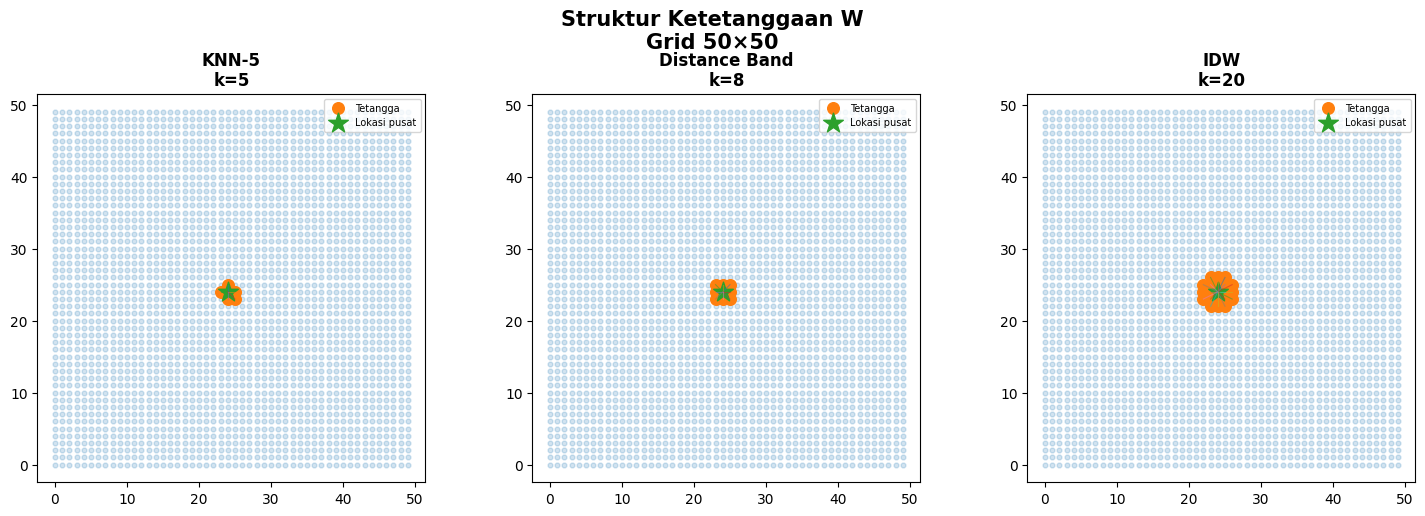

✅ E. 18 SKENARIO Y SELESAI


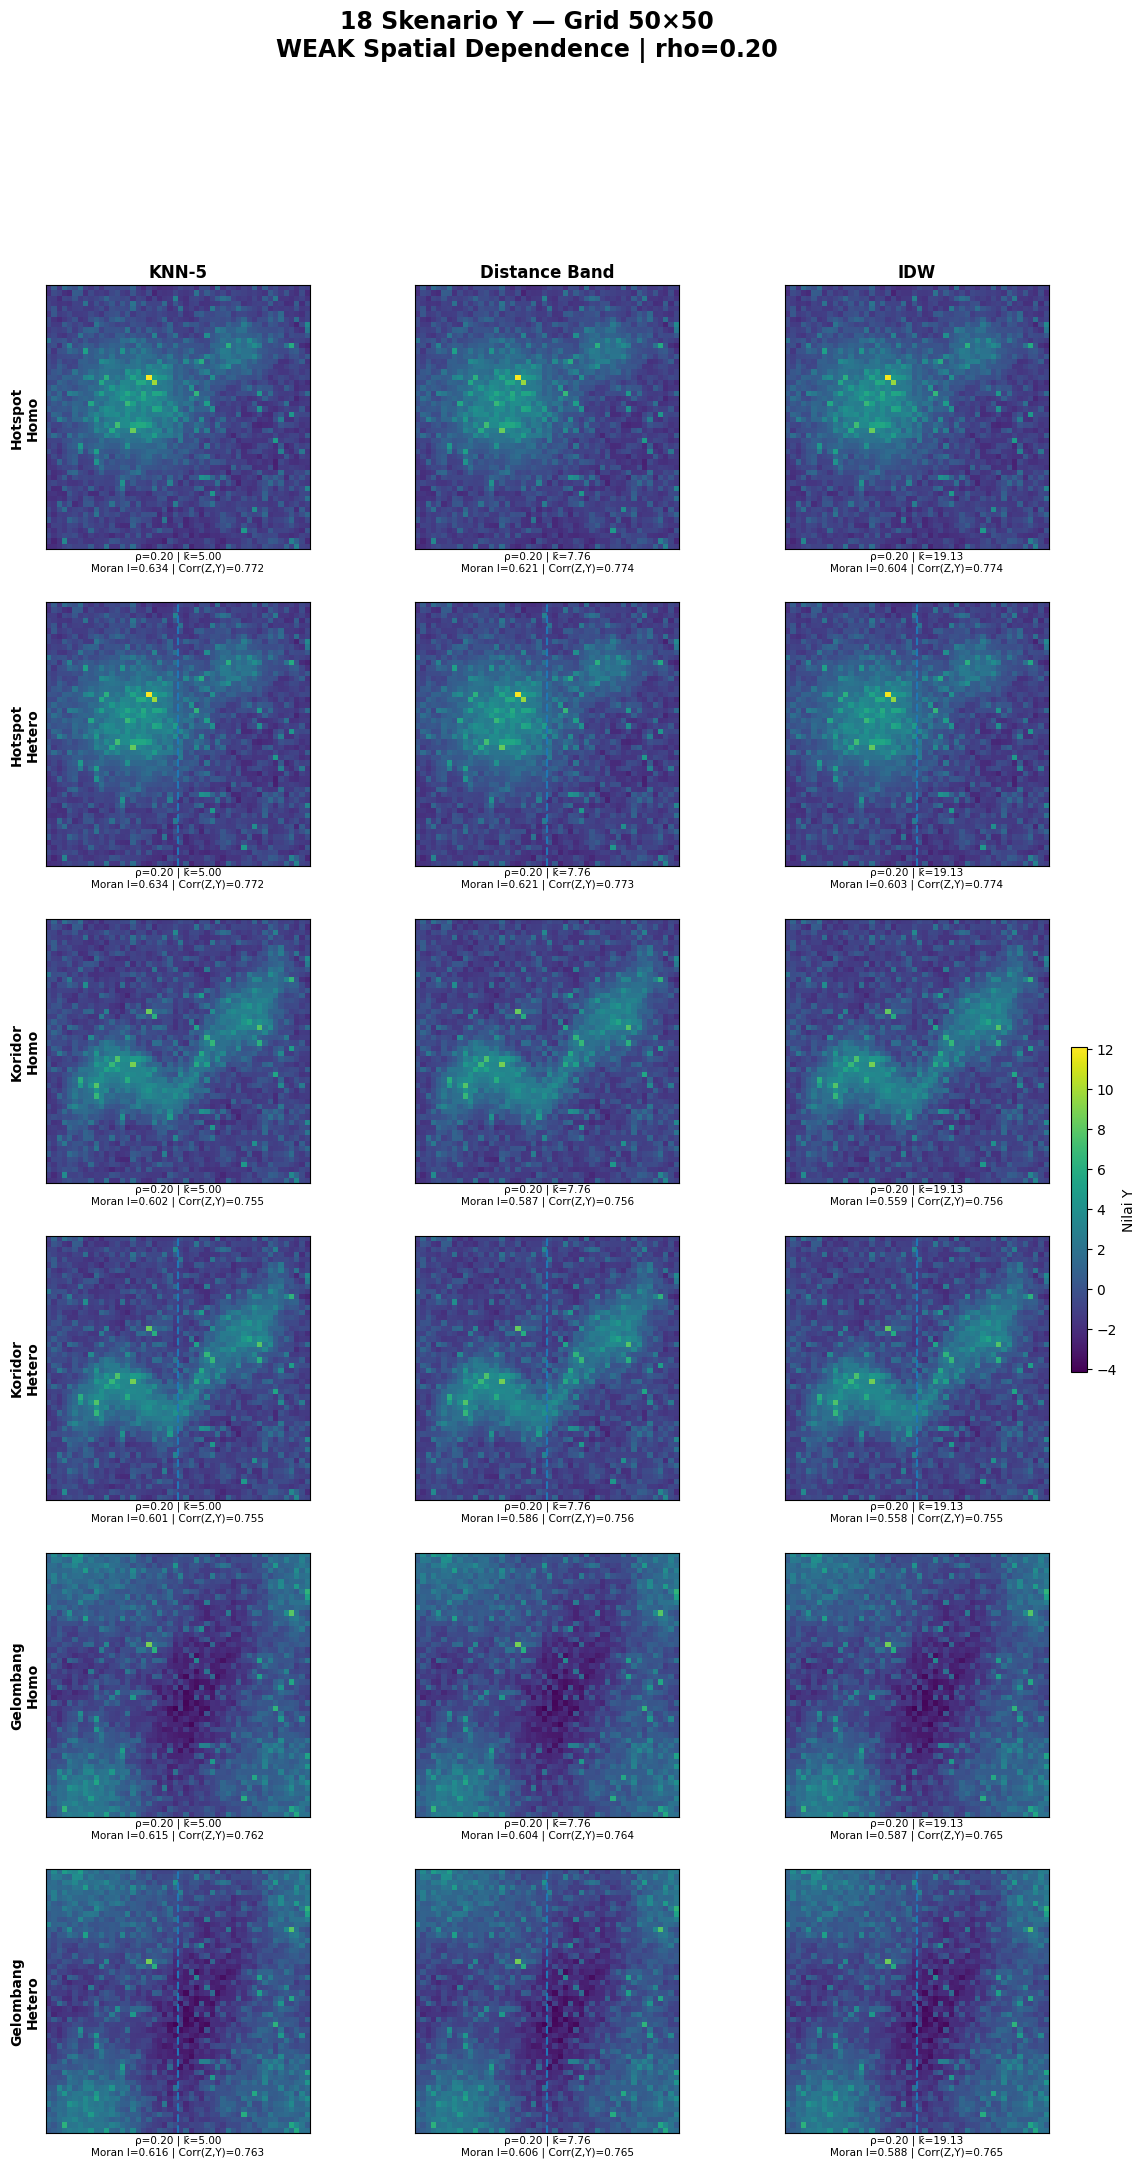

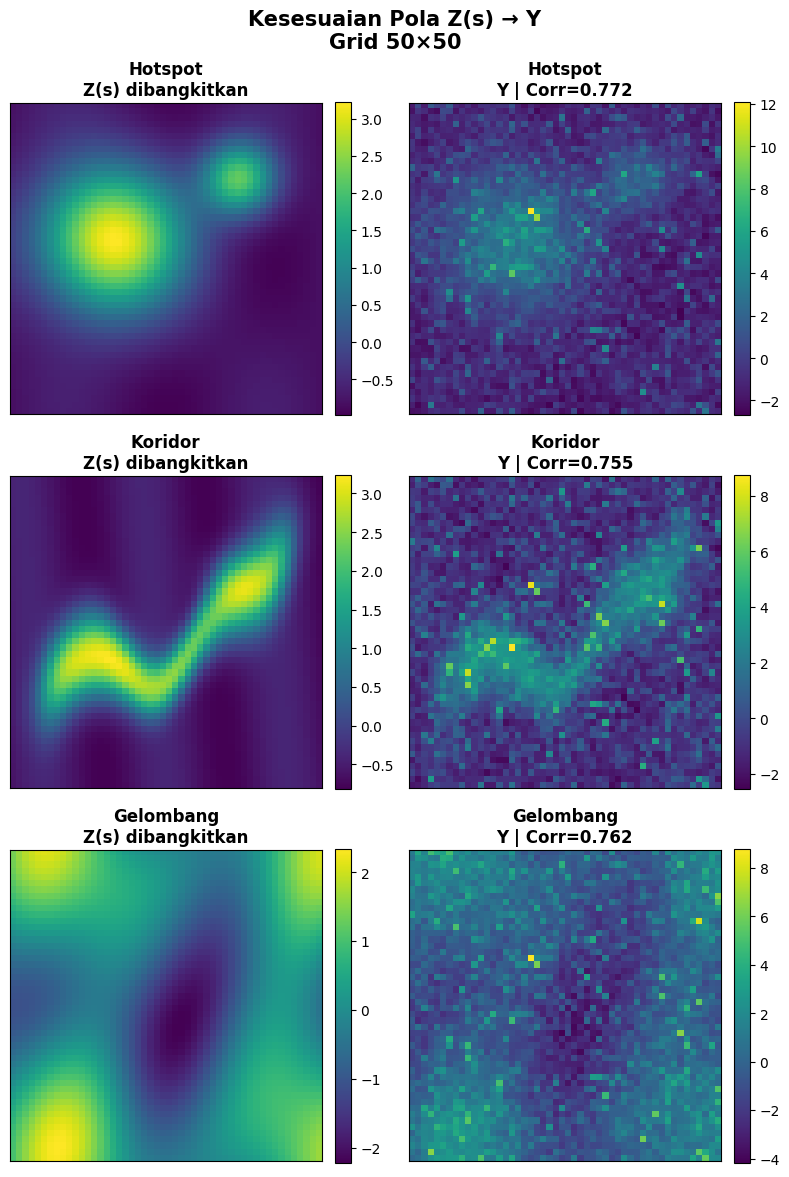

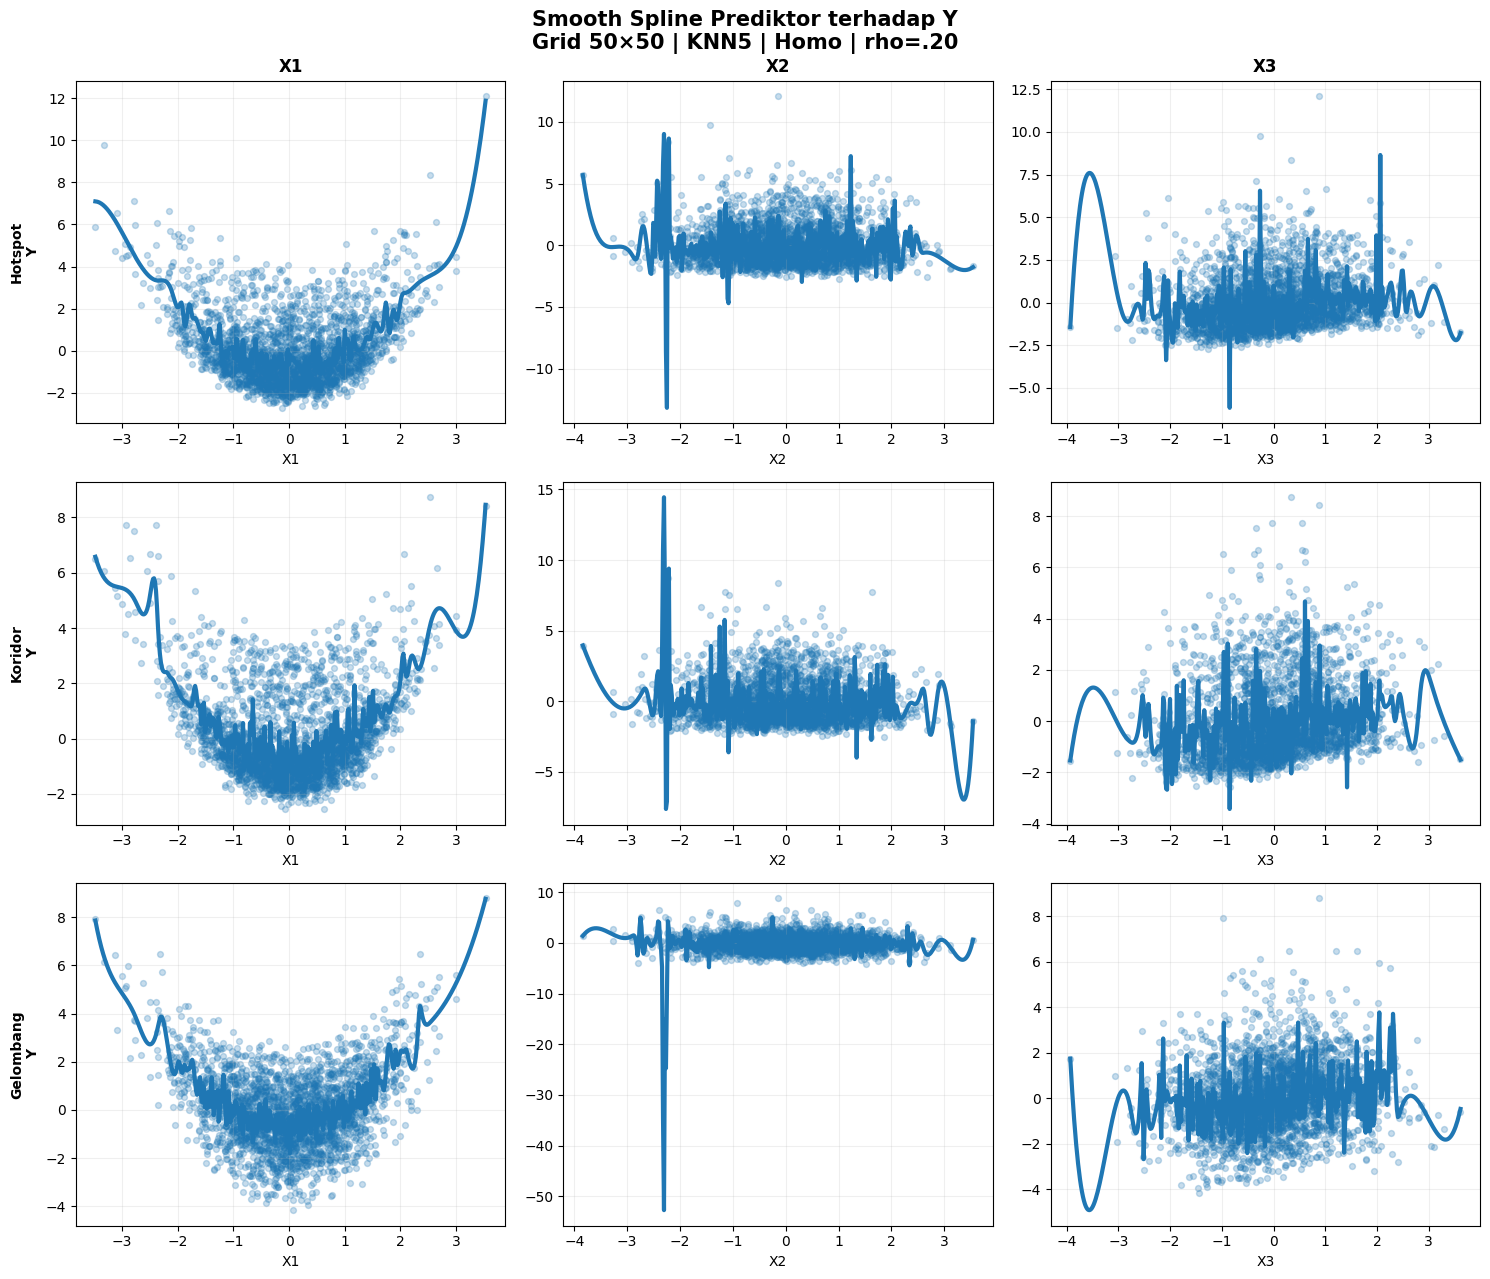



CEK BREUSCH-PAGAN — GRID 50×50 — WEAK rho=0.20:
  Pattern W_Method Error_Structure    BP_LM  BP_LM_pvalue     BP_F  BP_F_pvalue     BP_Expected     BP_Decision BP_Status
Gelombang DISTANCE   Heterogeneous 207.3201      0.000000 225.8865     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang DISTANCE     Homogeneous   0.2444      0.621023   0.2443     0.621189   Homoskedastik   Homoskedastik      PASS
Gelombang      IDW   Heterogeneous 207.3201      0.000000 225.8865     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang      IDW     Homogeneous   0.2444      0.621023   0.2443     0.621189   Homoskedastik   Homoskedastik      PASS
Gelombang     KNN5   Heterogeneous 207.3201      0.000000 225.8865     0.000000 Heteroskedastik Heteroskedastik      PASS
Gelombang     KNN5     Homogeneous   0.2444      0.621023   0.2443     0.621189   Homoskedastik   Homoskedastik      PASS
  Hotspot DISTANCE   Heterogeneous 207.3201      0.000000 225.8865     0.000000 Heteroskedastik 

In [ ]:
# ================================================================
# FILE WEAK — rho = 0.20
# CELL 5 — GRID 50×50
#
# + FINALISASI SELURUH FILE WEAK
# ================================================================


# ================================================================
# JALANKAN GRID50
# ================================================================

WEAK_GRID50 = run_weak_grid(
    50
)


In [ ]:
# ================================================================
# GABUNG SUMMARY GRID10 - GRID50
# ================================================================

SUMMARY_WEAK_ALL = pd.concat(

    [
        WEAK_GRID10[
            "summary"
        ],

        WEAK_GRID20[
            "summary"
        ],

        WEAK_GRID30[
            "summary"
        ],

        WEAK_GRID40[
            "summary"
        ],

        WEAK_GRID50[
            "summary"
        ]
    ],

    ignore_index=True

)


print("\n")
print("=" * 160)

print(
    "SUMMARY WEAK rho=0.20 — SEMUA GRID"
)

print("=" * 160)


print(

    SUMMARY_WEAK_ALL

    .round({

        "Rho":
            2,

        "BP_Homo_LM":
            4,

        "BP_Homo_p":
            6,

        "BP_Hetero_LM":
            4,

        "BP_Hetero_p":
            6,

        "Homo_Var_Ratio":
            4,

        "Hetero_Var_Ratio":
            4,

        "Mean_Moran_I":
            4,

        "Min_Moran_I":
            4,

        "Max_Moran_I":
            4,

        "Mean_Corr_Z_Y":
            4,

        "Min_Corr_Z_Y":
            4,

        "Max_Corr_Z_Y":
            4

    })

    .to_string(
        index=False
    )

)


# ================================================================
# GABUNG BP SEMUA GRID
# ================================================================

BP_WEAK_ALL = pd.concat(

    [
        WEAK_GRID10[
            "bp"
        ].assign(
            Grid="10x10"
        ),

        WEAK_GRID20[
            "bp"
        ].assign(
            Grid="20x20"
        ),

        WEAK_GRID30[
            "bp"
        ].assign(
            Grid="30x30"
        ),

        WEAK_GRID40[
            "bp"
        ].assign(
            Grid="40x40"
        ),

        WEAK_GRID50[
            "bp"
        ].assign(
            Grid="50x50"
        )

    ],

    ignore_index=True

)


print("\n")
print("=" * 160)

print(
    "CEK BREUSCH-PAGAN — SEMUA GRID WEAK:"
)

print("=" * 160)


print(

    BP_WEAK_ALL[

        [
            "Grid",
            "Pattern",
            "W_Method",
            "Error_Structure",
            "BP_LM",
            "BP_LM_pvalue",
            "BP_F",
            "BP_F_pvalue",
            "BP_Expected",
            "BP_Decision",
            "BP_Status"
        ]

    ]

    .round({

        "BP_LM":
            4,

        "BP_LM_pvalue":
            6,

        "BP_F":
            4,

        "BP_F_pvalue":
            6

    })

    .to_string(
        index=False
    )

)


# ================================================================
# SAVE SUMMARY SEMUA GRID
# ================================================================

SUMMARY_WEAK_ALL.to_csv(

    BASE_OUTPUT_WEAK

    /

    "SUMMARY_WEAK_ALL_GRID.csv",

    index=False

)


BP_WEAK_ALL.to_csv(

    BASE_OUTPUT_WEAK

    /

    "BREUSCH_PAGAN_WEAK_ALL_GRID.csv",

    index=False

)


# ================================================================
# ZIP SELURUH WEAK
# ================================================================

ZIP_WEAK = Path(

    "/content/"
    "WEAK_RHO020_ALL_GRID.zip"

)


with zipfile.ZipFile(

    ZIP_WEAK,

    "w",

    compression=
        zipfile.ZIP_DEFLATED

) as zipf:


    for file_path in (

        BASE_OUTPUT_WEAK
        .rglob("*")

    ):


        if file_path.is_file():


            zipf.write(

                file_path,

                arcname=
                    file_path.relative_to(
                        BASE_OUTPUT_WEAK.parent
                    )

            )


print("\n")
print("=" * 100)

print(
    "🎉 WEAK rho=0.20 — GRID10 SAMPAI GRID50 SELESAI"
)

print("=" * 100)


print(
    "\n📦 ZIP:"
)

print(
    ZIP_WEAK
)



SUMMARY WEAK rho=0.20 — SEMUA GRID
 Grid    N  Rho  Scenario    Beta1     Beta2    Beta3  BP_Homo_LM  BP_Homo_p BP_Homo_Decision  BP_Hetero_LM  BP_Hetero_p BP_Hetero_Decision  Homo_Var_Ratio  Hetero_Var_Ratio  Mean_Moran_I  Min_Moran_I  Max_Moran_I  Mean_Corr_Z_Y  Min_Corr_Z_Y  Max_Corr_Z_Y  BP_All_PASS  Variance_All_PASS  Moran_All_PASS  Pattern_All_PASS
10x10  100  0.2        18 1.977831 -0.471961 1.308592      3.0051   0.083002    Homoskedastik       18.8247     0.000014    Heteroskedastik          1.6199            4.8596        0.3928       0.2854       0.4899         0.7481        0.6984        0.7742         True               True            True              True
20x20  400  0.2        18 1.977831 -0.471961 1.308592      1.1785   0.277655    Homoskedastik       50.3429     0.000000    Heteroskedastik          1.1534            3.4601        0.5366       0.4279       0.5985         0.7676        0.7580        0.7798         True               True            True             